# Dat200 CA5

## Group 3 Members
- Stig Espen Paulsberg
- Vinicius Millan
- Zaur Kambiev

Kaggle team `Group 3`

# Imports

In [121]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    PolynomialFeatures,
    StandardScaler,
)


# Reading data

In [3]:
df = pd.read_csv("data/train.csv", index_col=0)

# Data exploration and visualization

In [4]:
print("Data shape:", df.shape)
df.head()

Data shape: (367500, 16)


,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
id,,,,,,,,,,,,,,,,
193355,55.0,NaN,9.0,20.0,0.900000,3.7,1.1,129.0,47.7,1.0,Never,3.0,1.8,8.0,8.0,27
509850,23.0,6.8,8.0,66.0,-3.634081,NaN,1.8,108.0,29.9,7.0,Never,63.0,0.9,5.0,5.0,28
413954,70.0,9.4,9.0,13.0,2.100000,9.5,5.0,137.0,NaN,2.0,Never,1.0,2.4,8.0,5.0,25
94859,40.0,7.5,10.0,200.0,1.600000,5.0,0.5,124.0,NaN,0.0,Never,7.0,0.9,NaN,8.0,29
18214,18.0,6.9,6.0,81.0,NaN,3.6,1.2,118.0,43.2,2.0,Never,0.0,0.5,5.0,10.0,26


### Missing values and duplicate rows

* Let's count the missing values in each column.

In [5]:
pd.DataFrame({"Missing rate": df.isna().mean(),})

,Missing rate
age,0.059448
sleep_duration_hrs,0.073951
sleep_quality_score,0.026661
cardio_mins_wk,0.032963
water_intake_liters,0.023214
screen_time_recreational_hrs,0.077918
social_media_hrs,0.014403
blood_pressure_sys,0.026424
diet_ultra_processed_pct,0.036269
diet_omega3_freq,0.061260


* Every feature has missing values. Let's check whether they occur in the same rows or are spread across different rows.

In [6]:
n = df.isna().any(axis=1).sum()
print(f"Rows with missing values: {n} ({n / df.shape[0]:.2%})")

Rows with missing values: 197225 (53.67%)


* The share is huge! We can't just remove all these rows, so we will use imputation instead.

* Let's check if we have duplicates.

In [7]:
n = df.duplicated().sum()
print(f"Diplicates: {n} ({n / df.shape[0]:.2%})")

Diplicates: 17500 (4.76%)


* Let's remove the duplicate rows to avoid data leakage during cross-validation.

In [8]:
df = df.drop_duplicates()

### Distributions and outliers

#### Feature type: Demographics & Biometrics

* `age`: According to the dataset description, participants are aged between 18 and 90. Let's check the age distribution. For this, we define a function that plots the binned distribution of a feature, using a logarithmic scale for the counts so that rare values are easier to see.

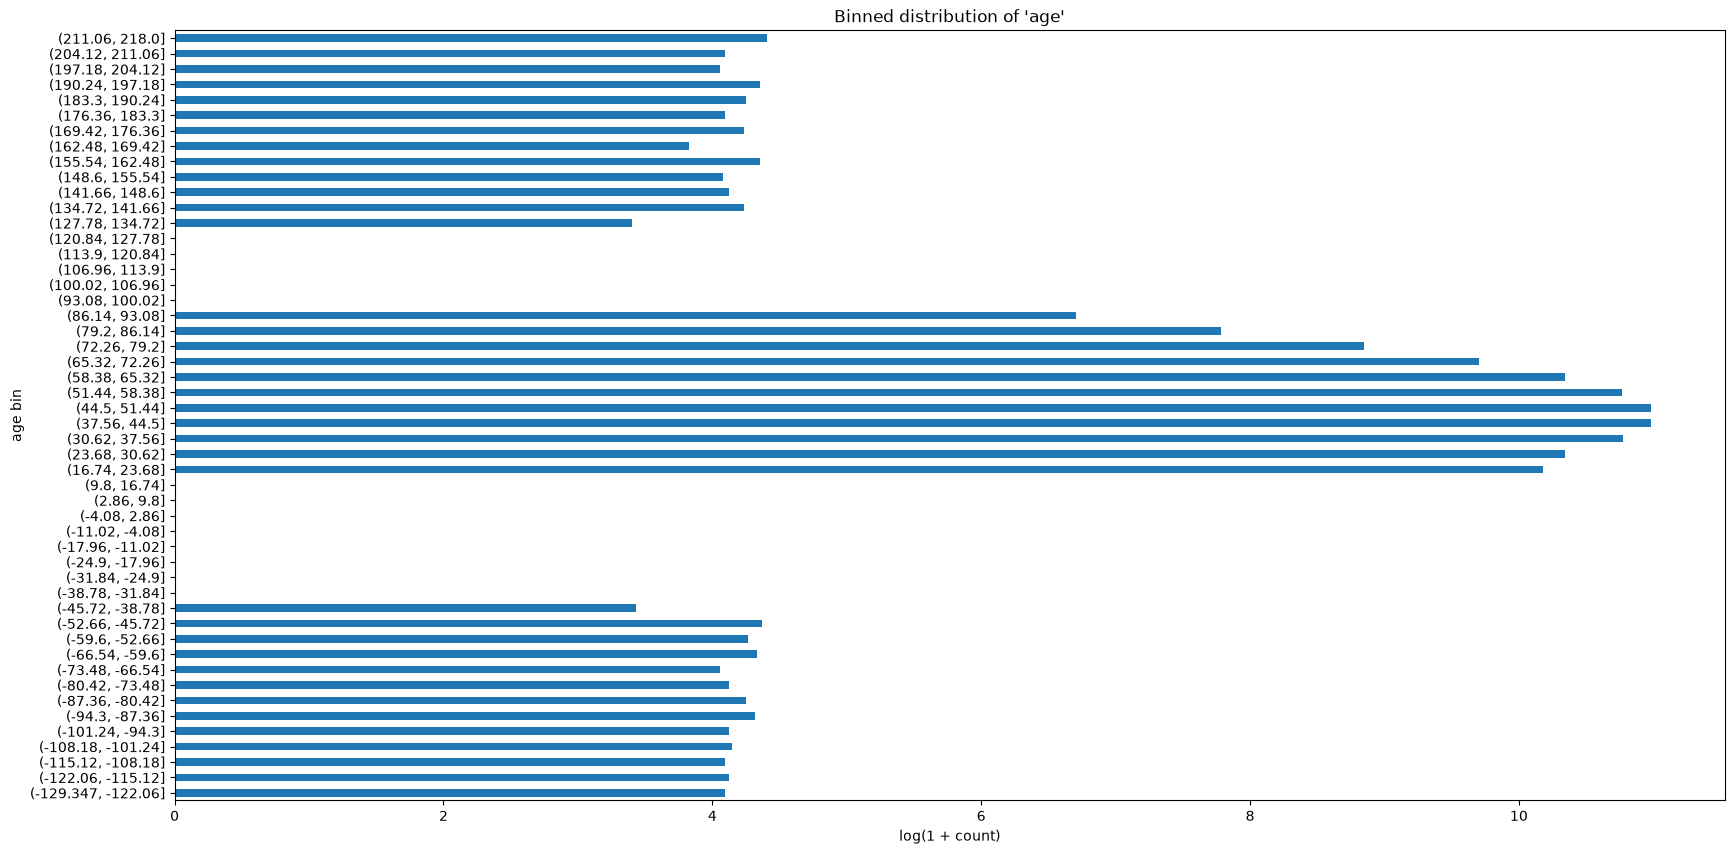

In [9]:
def plot_binned_distribution(df, feature, num_bins=50):
    plt.figure(figsize=(20, 10))

    s = df[feature]

    # small number of unique values -> simple barplot
    if s.nunique() <= num_bins:
        (
            s.value_counts()
            .apply(np.log1p)
            .sort_index()
            .plot.bar()
        )
        plt.title(f"Distribution of '{feature}'")
        plt.xlabel(feature)
        plt.ylabel("log(1 + count)")
        plt.tick_params(axis="x", labelrotation=45)
    else:
        (
            pd.cut(s, bins=num_bins)
            .value_counts()
            .apply(np.log1p)
            .sort_index()
            .plot.barh()
        )
        plt.title(f"Binned distribution of '{feature}'")
        plt.xlabel("log(1 + count)")
        plt.ylabel(f"{feature} bin")


plot_binned_distribution(df, "age")

* There are some obvious outliers with negative or implausibly high ages. Let's take a closer look at the valid region.

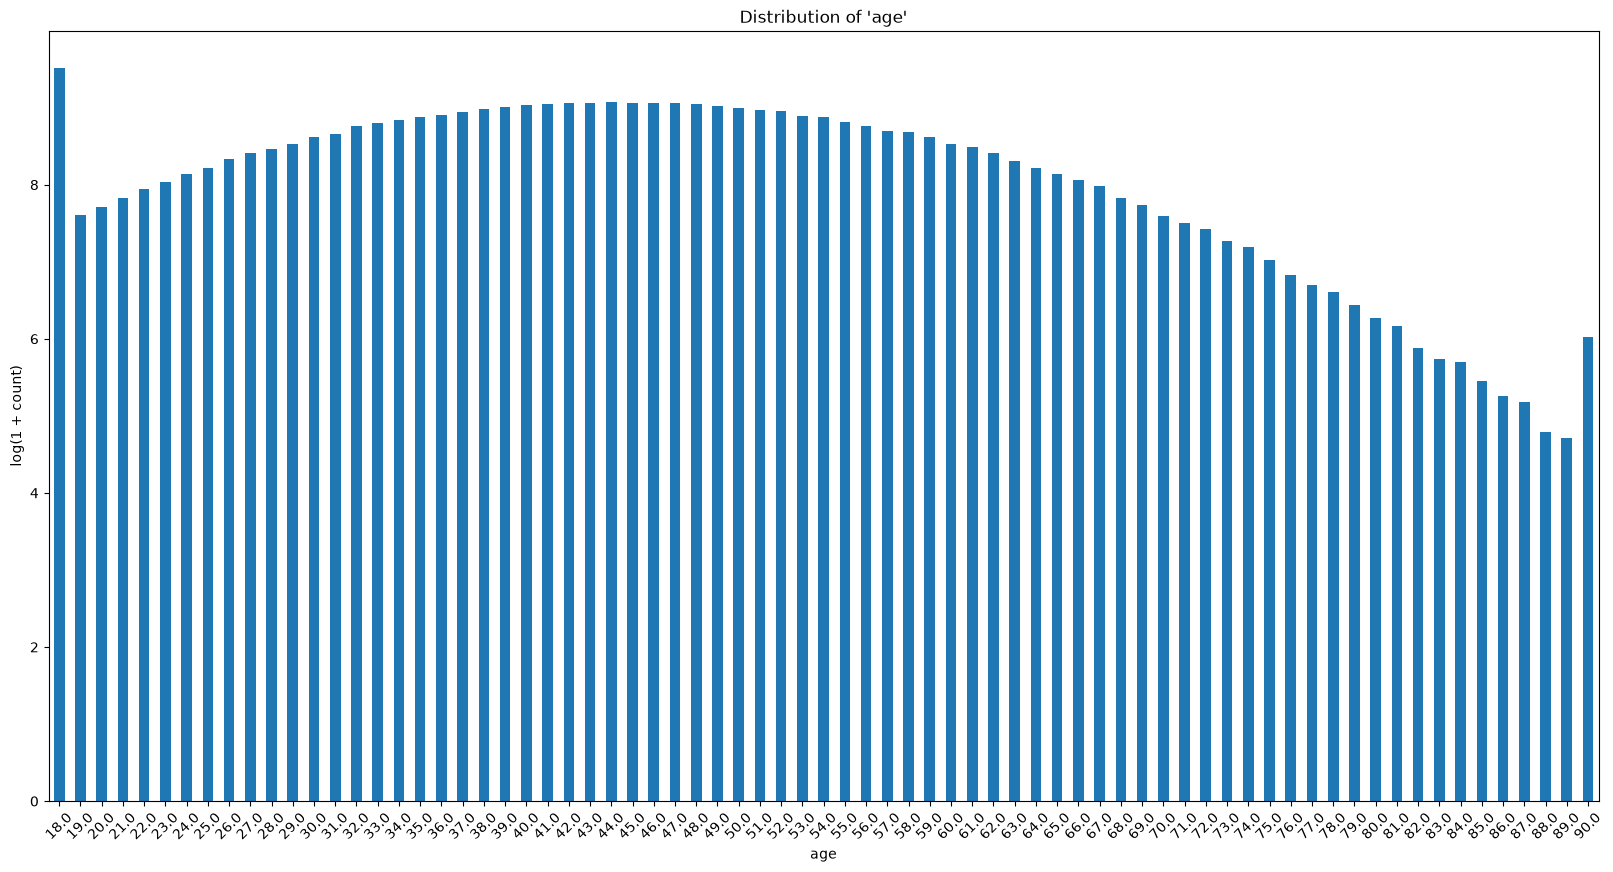

In [10]:
feature = "age"
region_mask = df[feature].between(15, 95)
plot_binned_distribution(df[region_mask], feature, num_bins=100)

* There are noticeable spikes at 18 and 90. They probably include participants whose real age lies outside the stated range.

* `blood_pressure_sys`: The dataset description does not specify a valid range for this feature. Let's plot the binned distribution.

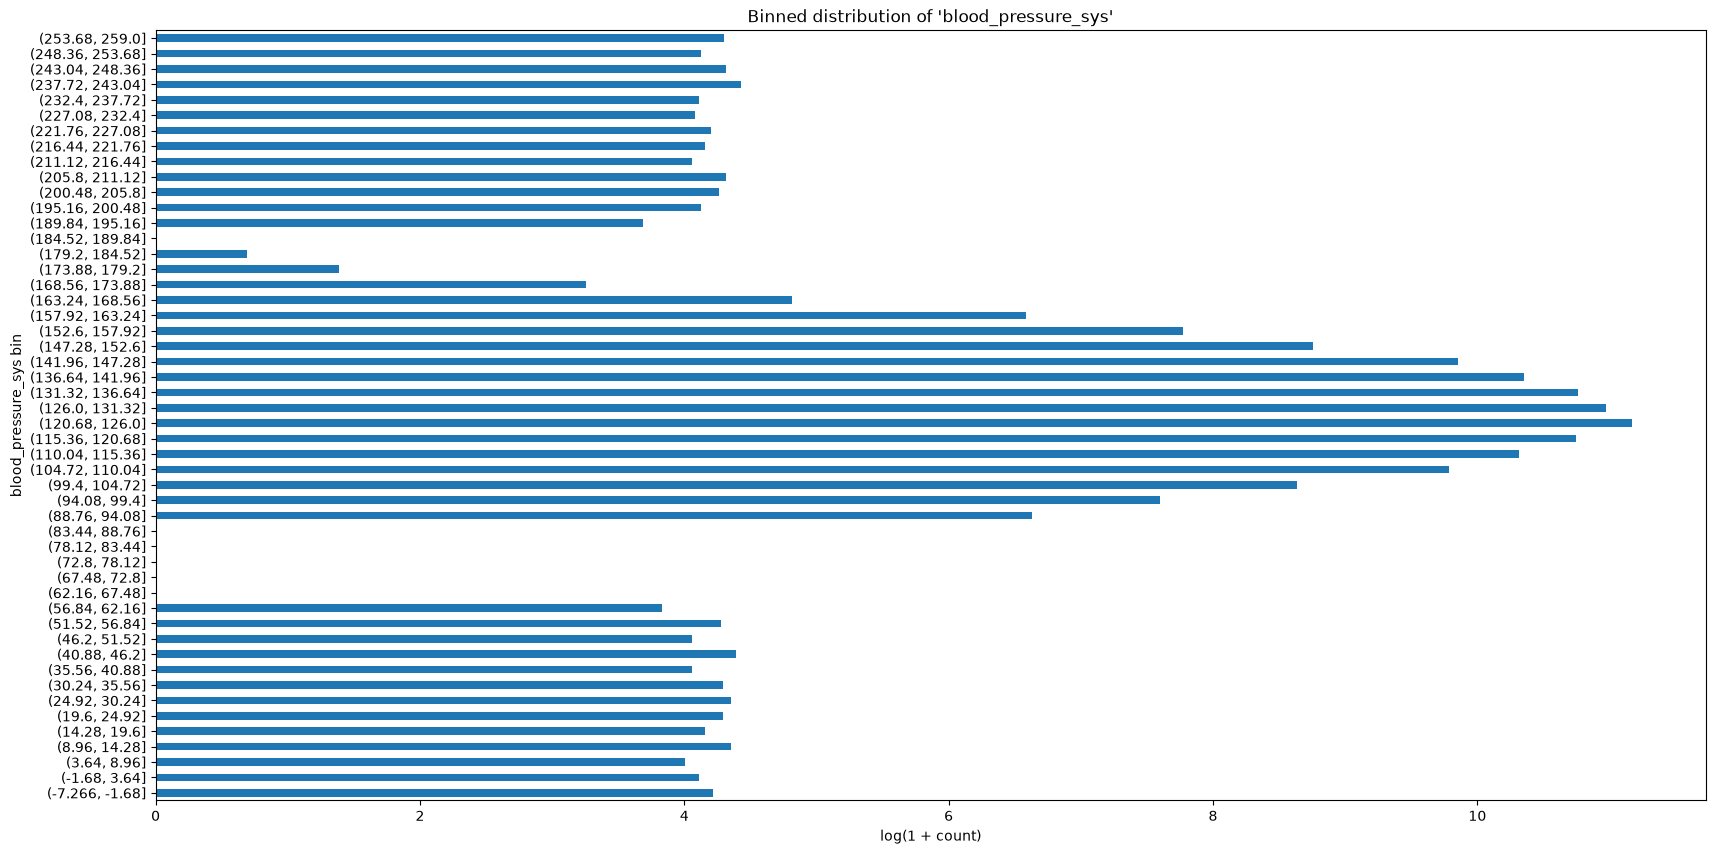

In [11]:
plot_binned_distribution(df, "blood_pressure_sys")

* There are empty bins near both ends of the main distribution, which suggests a valid range of roughly 88–185. Let's take a closer look at the regions near both boundaries.

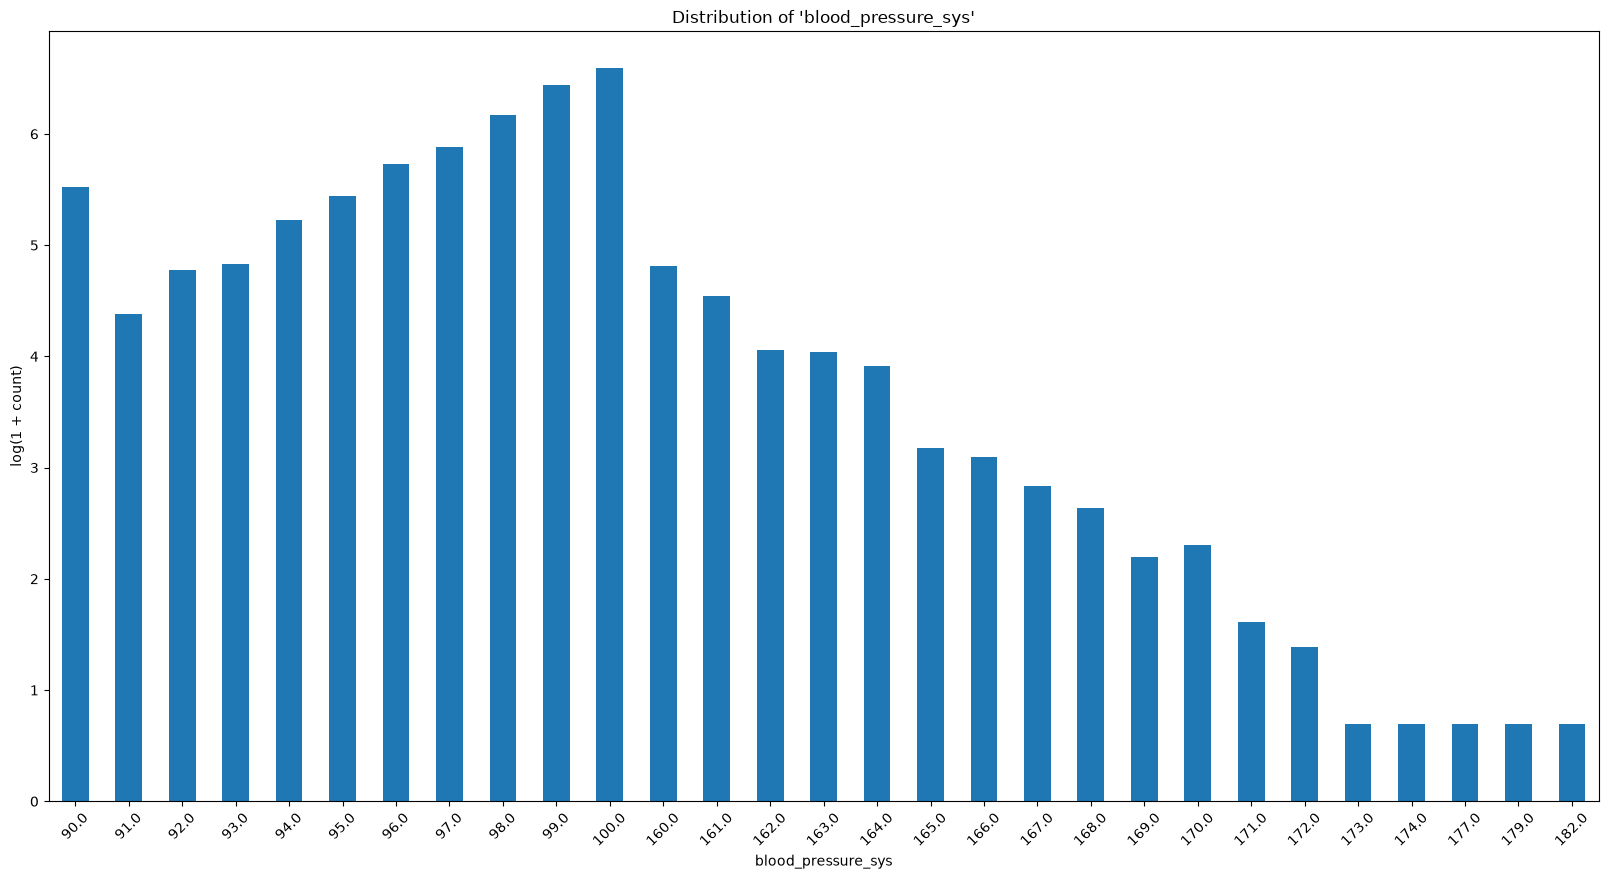

In [12]:
feature = "blood_pressure_sys"

# keep only values between 70–100 and 160–190
region_mask = df[feature].between(70, 100) | df[feature].between(160, 190)

plot_binned_distribution(df[region_mask], feature)

* The lower and upper cutoffs are 90 and 182. There is also a spike at 90.

#### Core Lifestyle Habits

* `sleep_duration_hrs`: Let's plot the binned distribution.

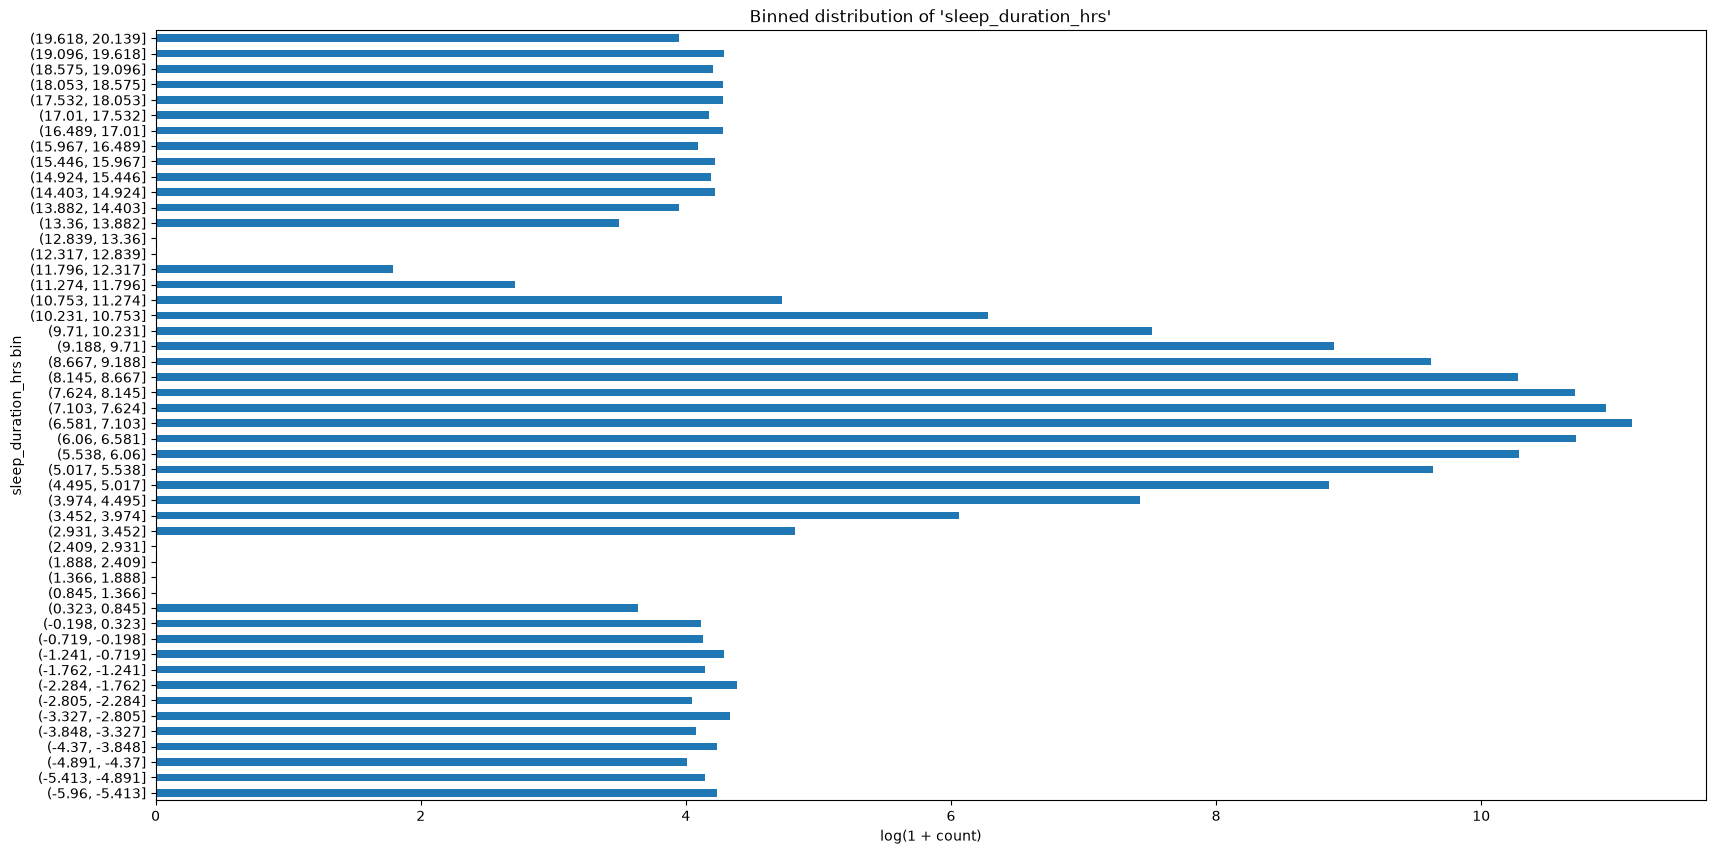

In [13]:
plot_binned_distribution(df, "sleep_duration_hrs")

* Based on the binned distribution, the valid range of `sleep_duration_hrs` appears to be 3–12 hours. We need a closer look here.

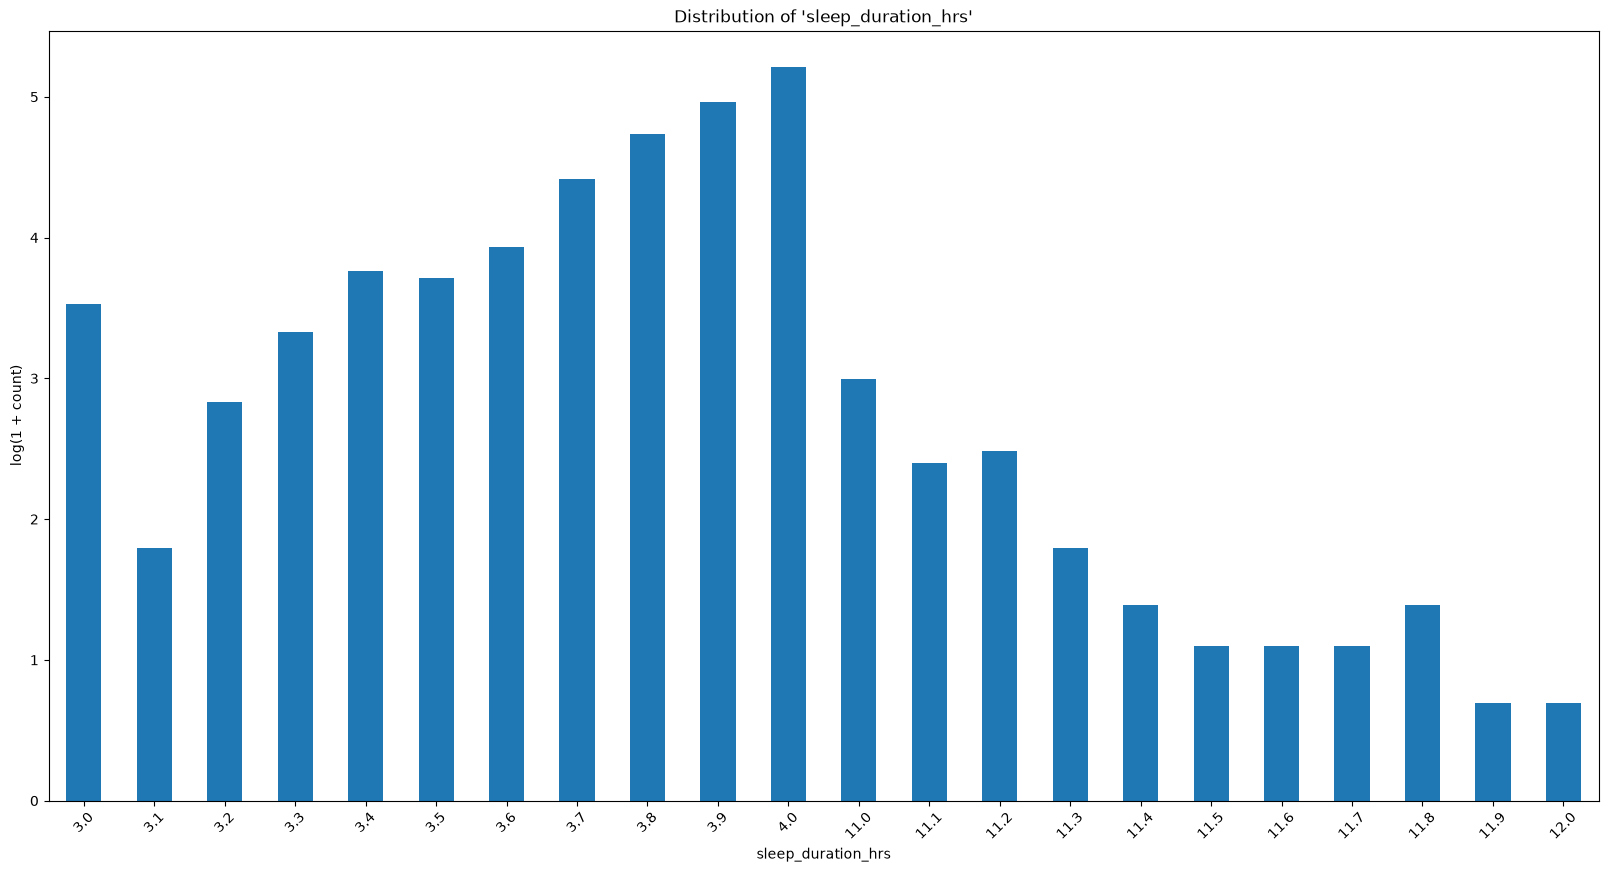

In [14]:
feature = "sleep_duration_hrs"

# keep only values between 2–4 and 11–13 hours
region_mask = df[feature].between(2, 4) | df[feature].between(11, 13)

plot_binned_distribution(df[region_mask], feature)

* The lower and upper cutoffs are 3 and 12. There is also a spike at 3.

* `sleep_quality_score`: The description states that valid values range from 1 to 10. Let's check it.

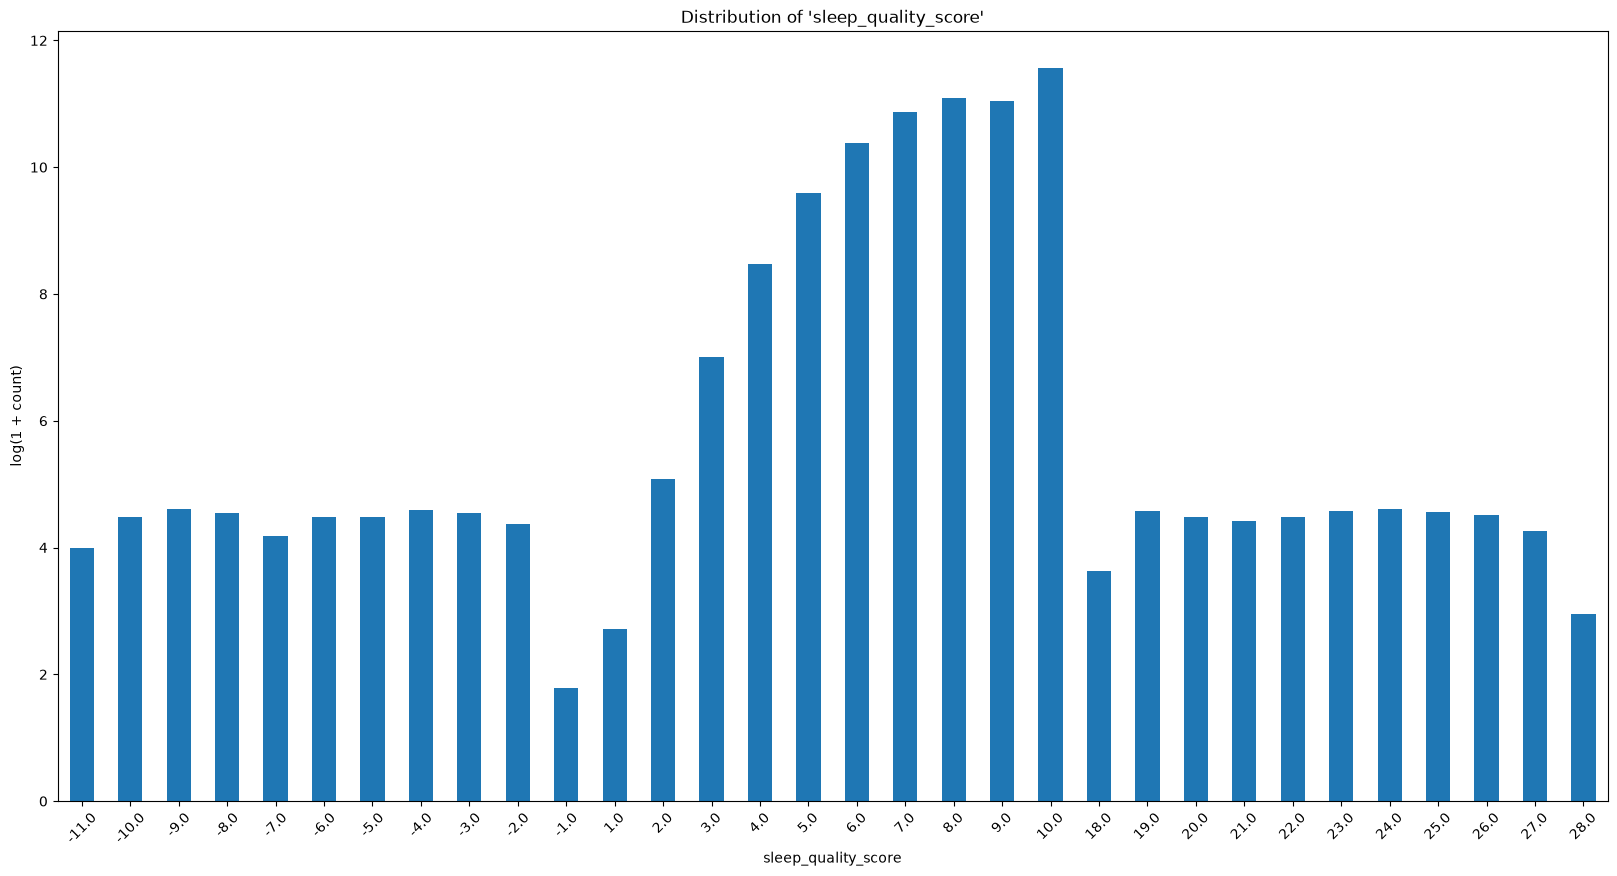

In [15]:
plot_binned_distribution(df, "sleep_quality_score")

* The values outside the 1–10 range look like noise.

* `cardio_mins_wk`: The values cannot be negative. Let's determine a plausible upper limit.

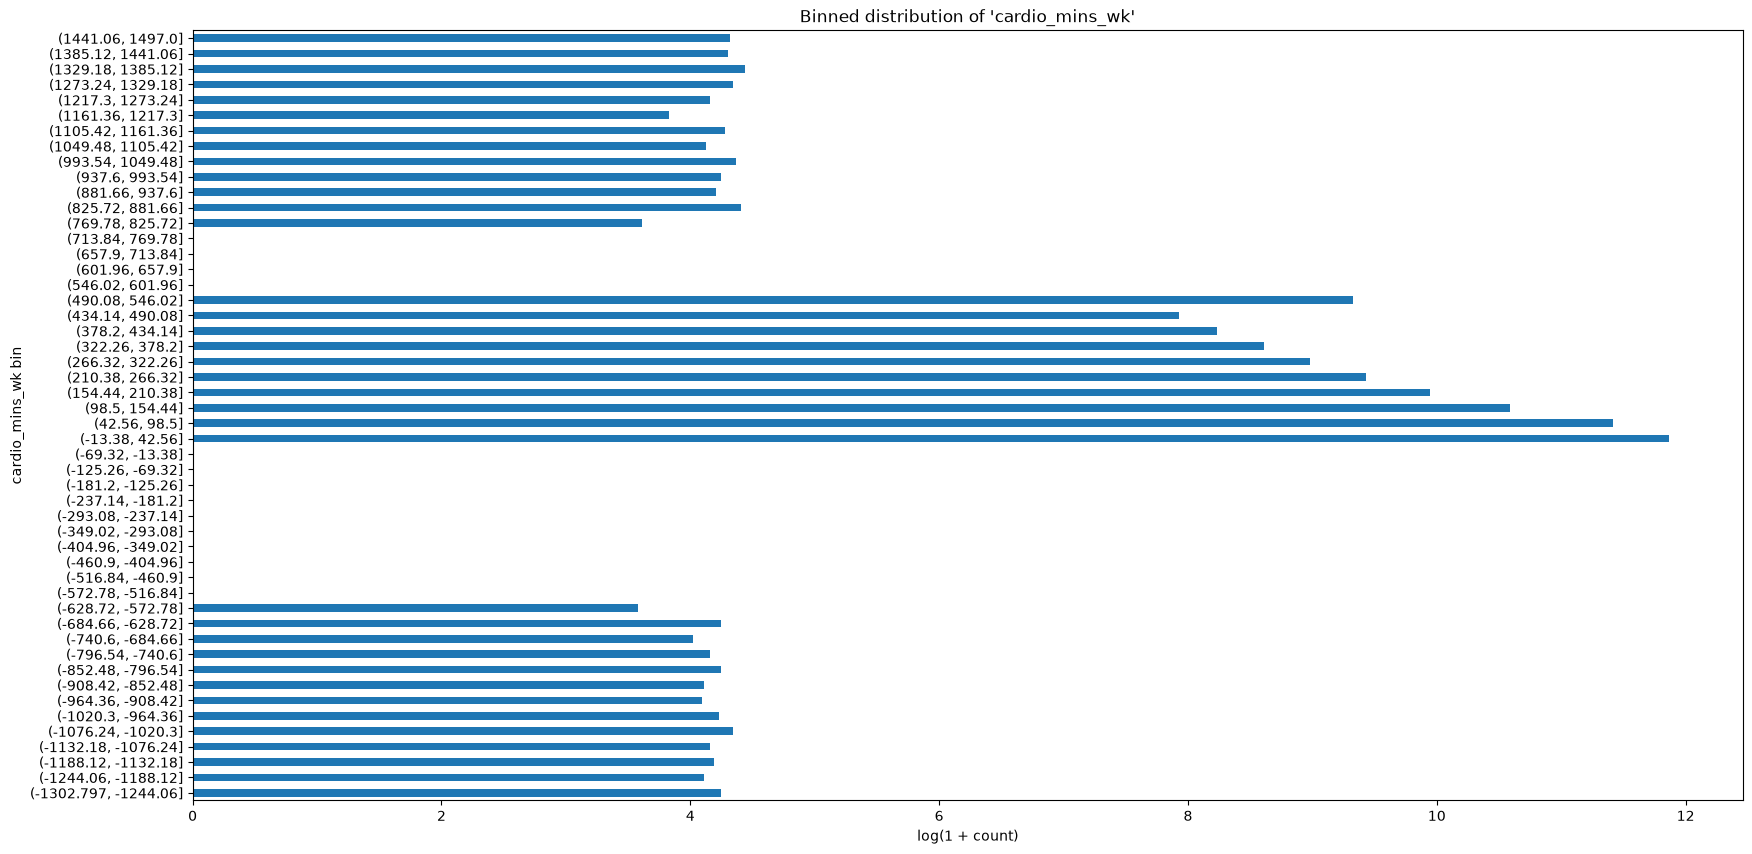

In [16]:
plot_binned_distribution(df, "cardio_mins_wk")

* We see a cutoff and a spike around 500. Let's examine this region more closely.

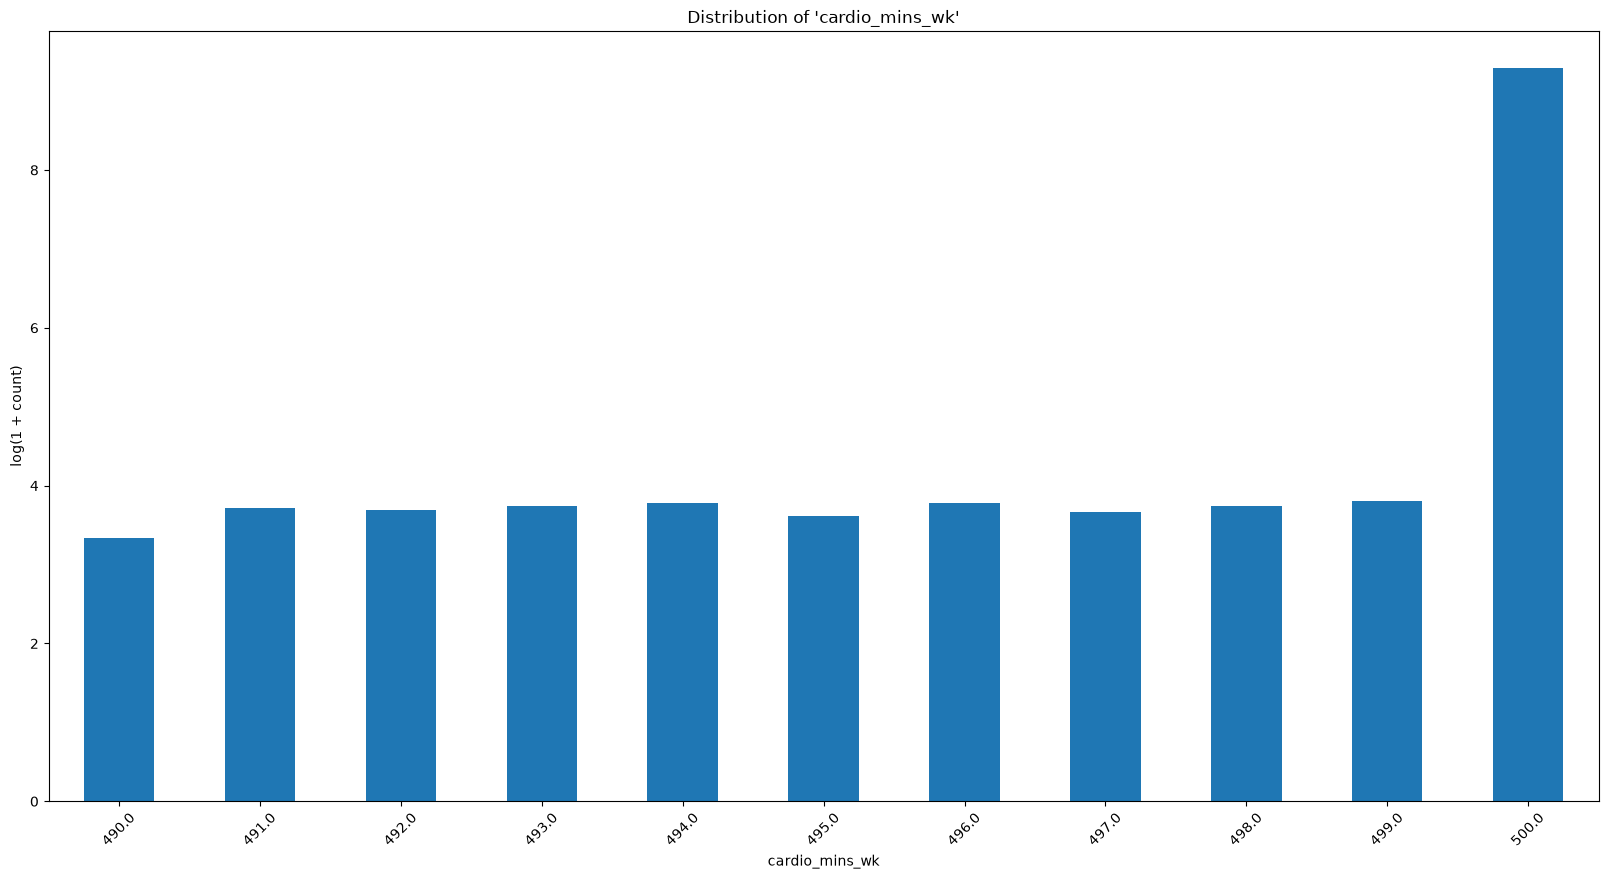

In [17]:
feature = "cardio_mins_wk"

# keep only values between 490 and 510
region_mask = df[feature].between(490, 510)

plot_binned_distribution(df[region_mask], feature)

* This confirms it: the valid values end with a spike at 500 minutes per week.

* `water_intake_liters`: Let's determine plausible lower and upper cutoffs.

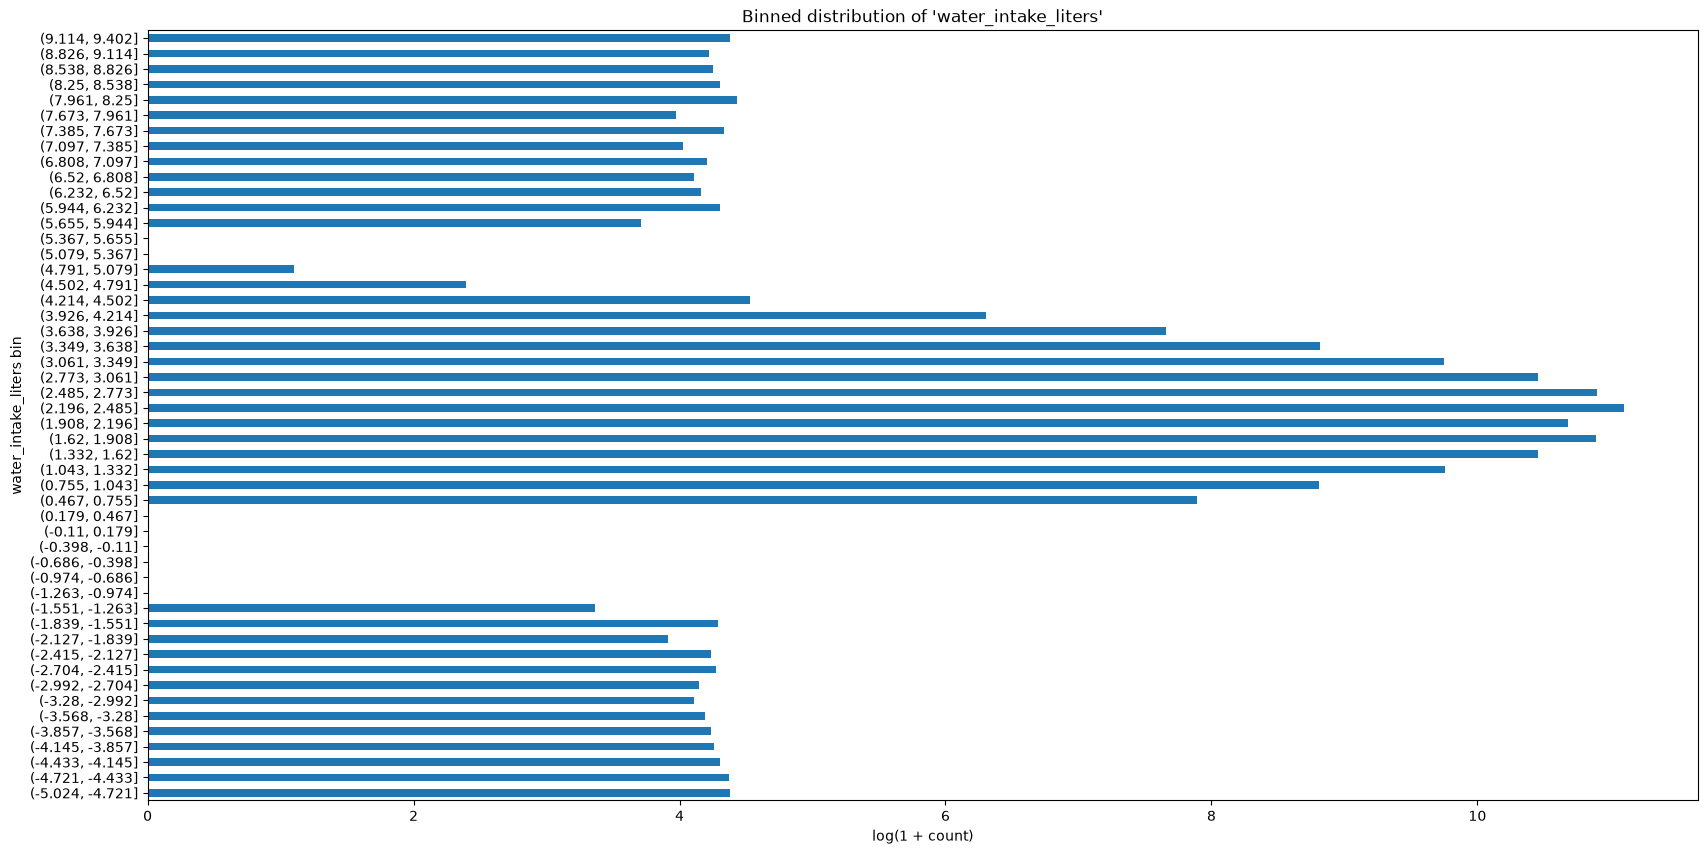

In [18]:
plot_binned_distribution(df, "water_intake_liters")

* Values must be non-negative, and a plausible upper cutoff is around 5 litres. Let's take a closer look at that region.

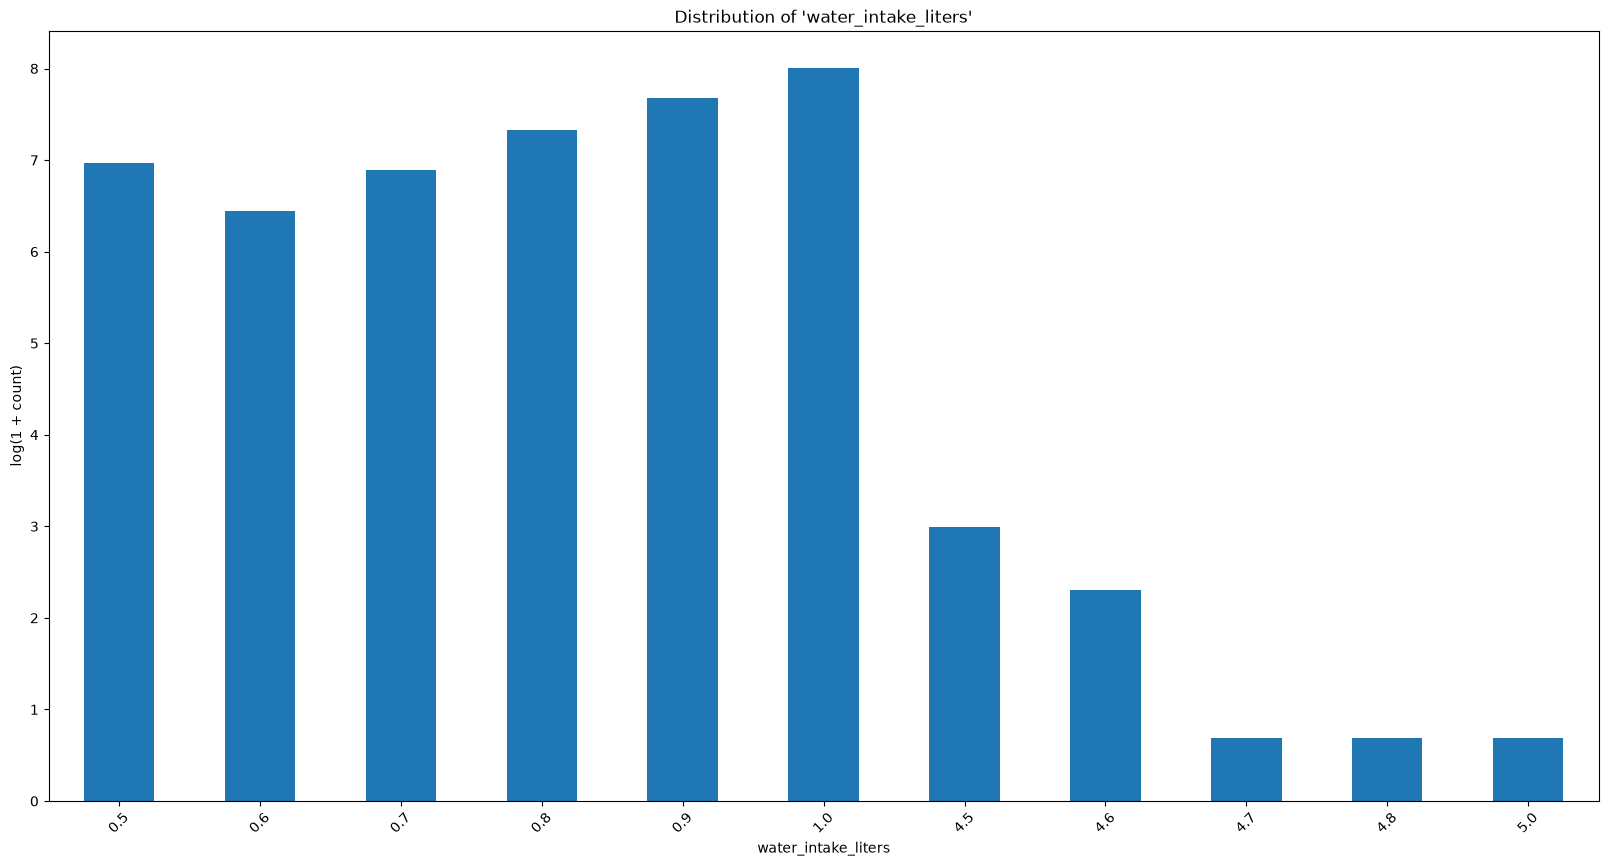

In [19]:
feature = "water_intake_liters"

# keep only values between 0–1 and 4.5–5.5 hours
region_mask = df[feature].between(0, 1) | df[feature].between(4.5, 5.5)

plot_binned_distribution(df[region_mask], feature)

* The lower and upper cutoffs are 0.5 and 5. 

* `screen_time_recreational_hrs`: Let's perform the same analysis.

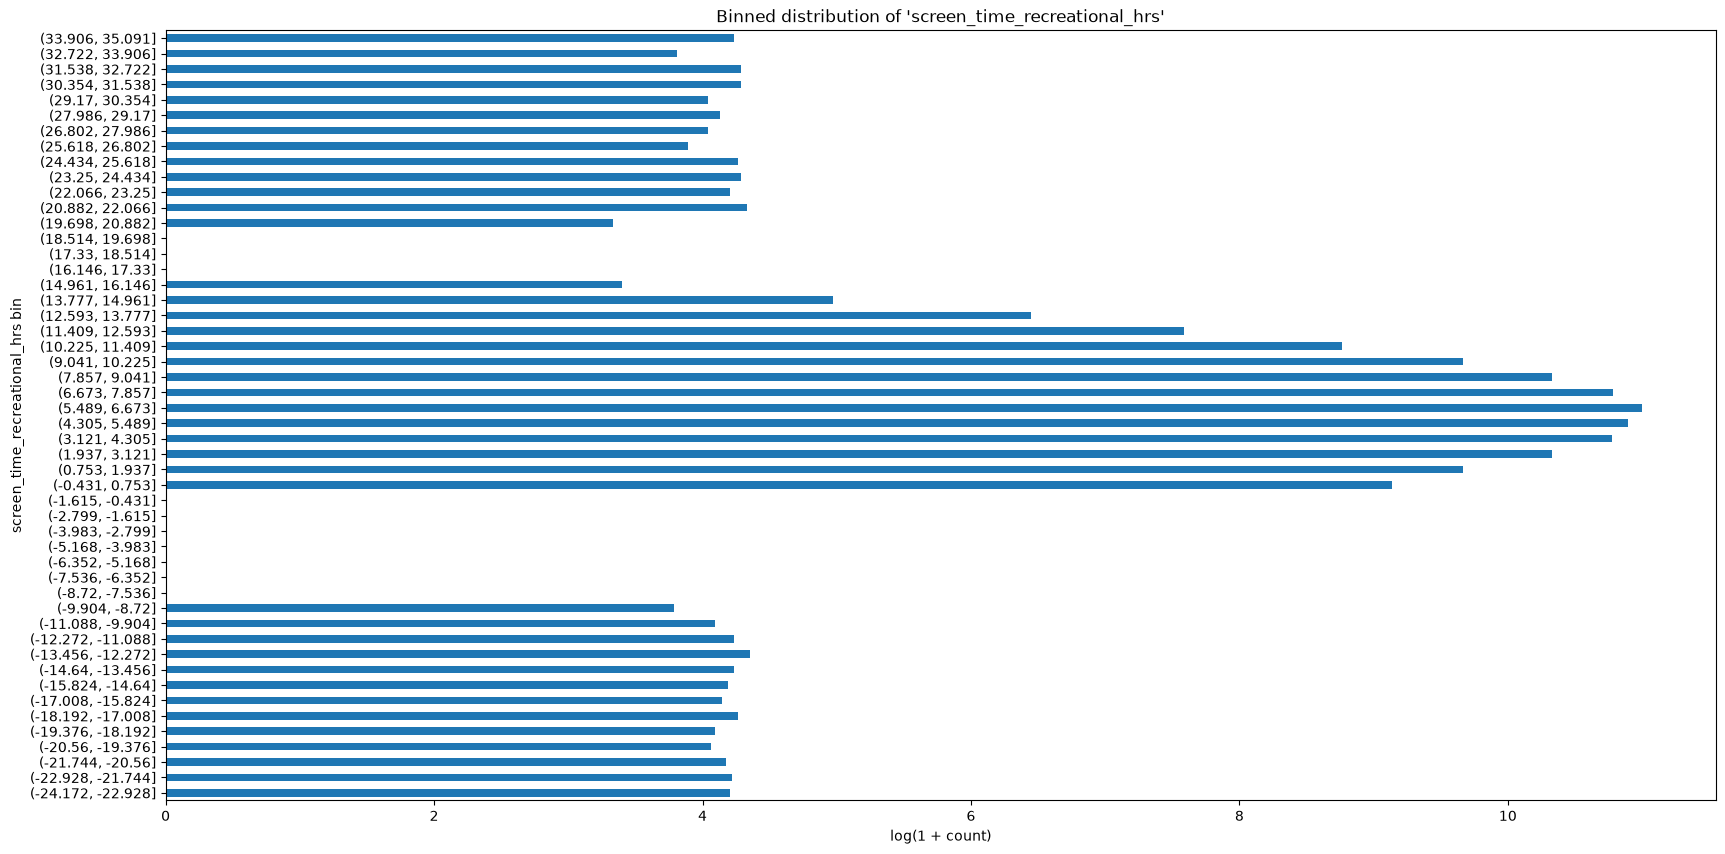

In [20]:
plot_binned_distribution(df, "screen_time_recreational_hrs")

* Let's take a closer look at the boundaries.

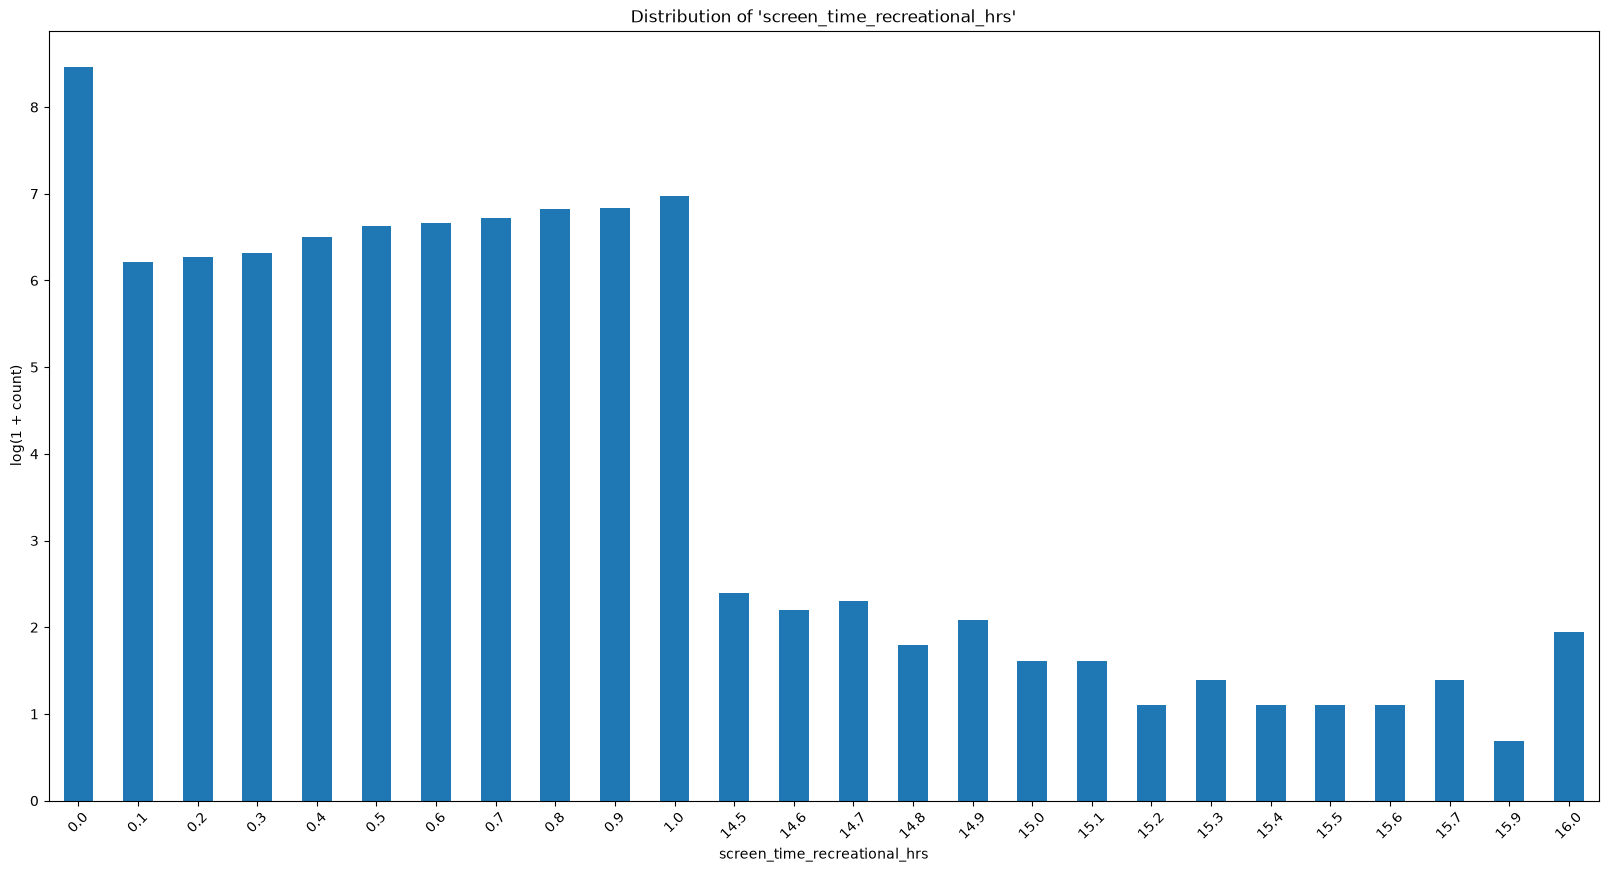

In [21]:
feature = "screen_time_recreational_hrs"

# keep only values between 0–1 and 14.5–16.5
region_mask = df[feature].between(0, 1) | df[feature].between(14.5, 16.5)

plot_binned_distribution(df[region_mask], feature)

* The upper cutoff is 16. There is a spike at 0 hours.

* `social_media_hrs`: Let's start with a binned distribution again.

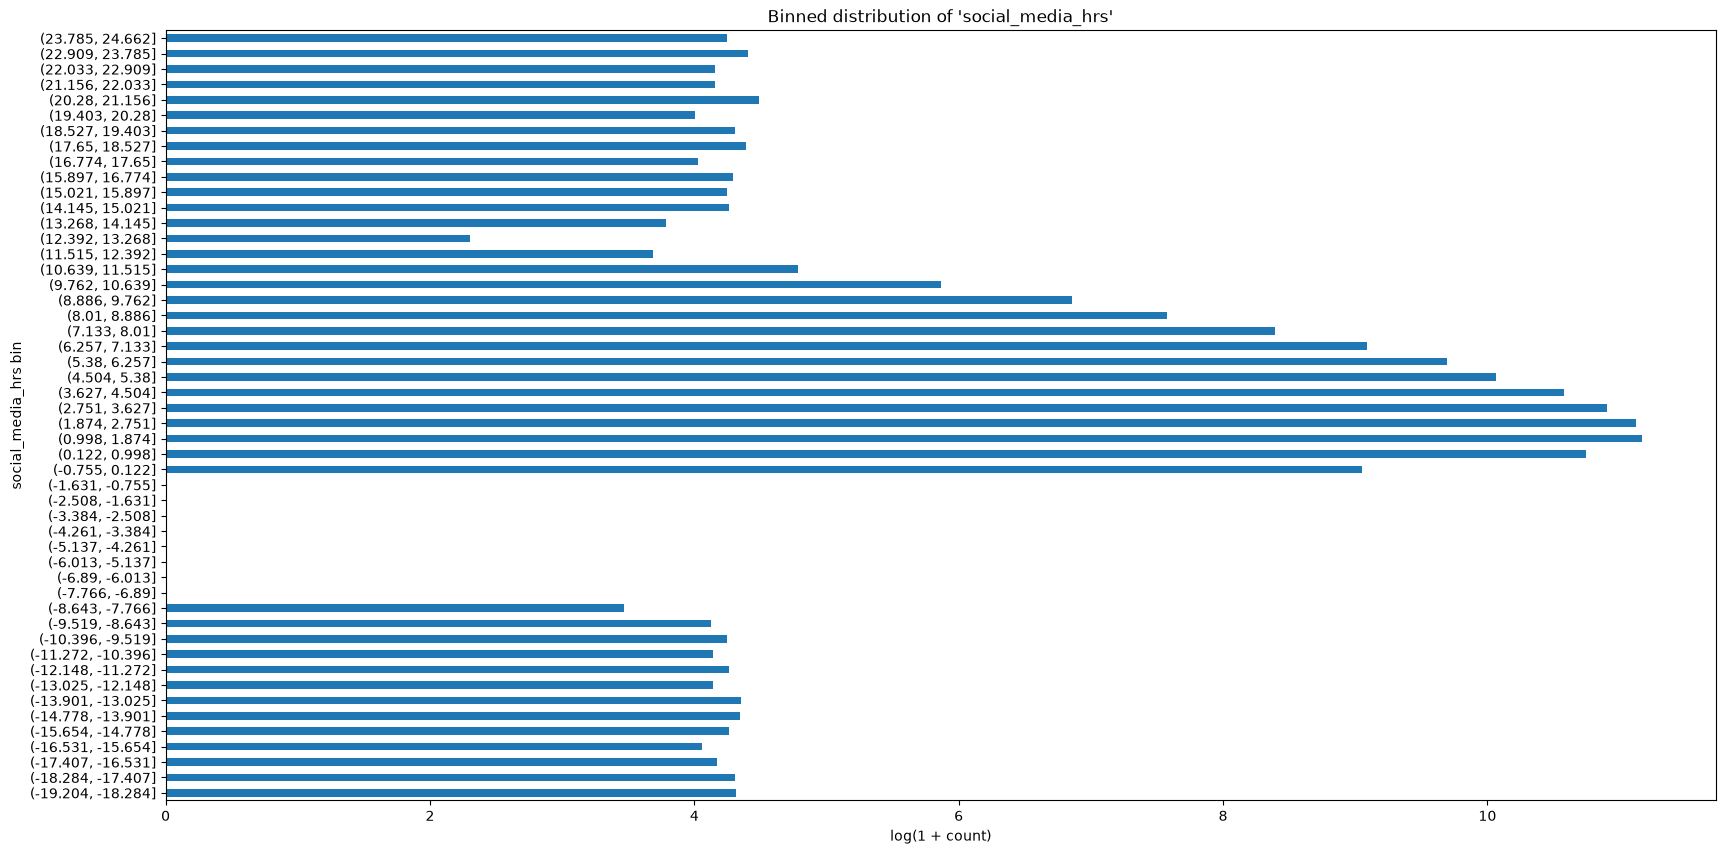

In [22]:
plot_binned_distribution(df, "social_media_hrs")

* The upper cutoff is around 13 hours, but the exact value is unclear. Let's take a closer look at the values in that region. 

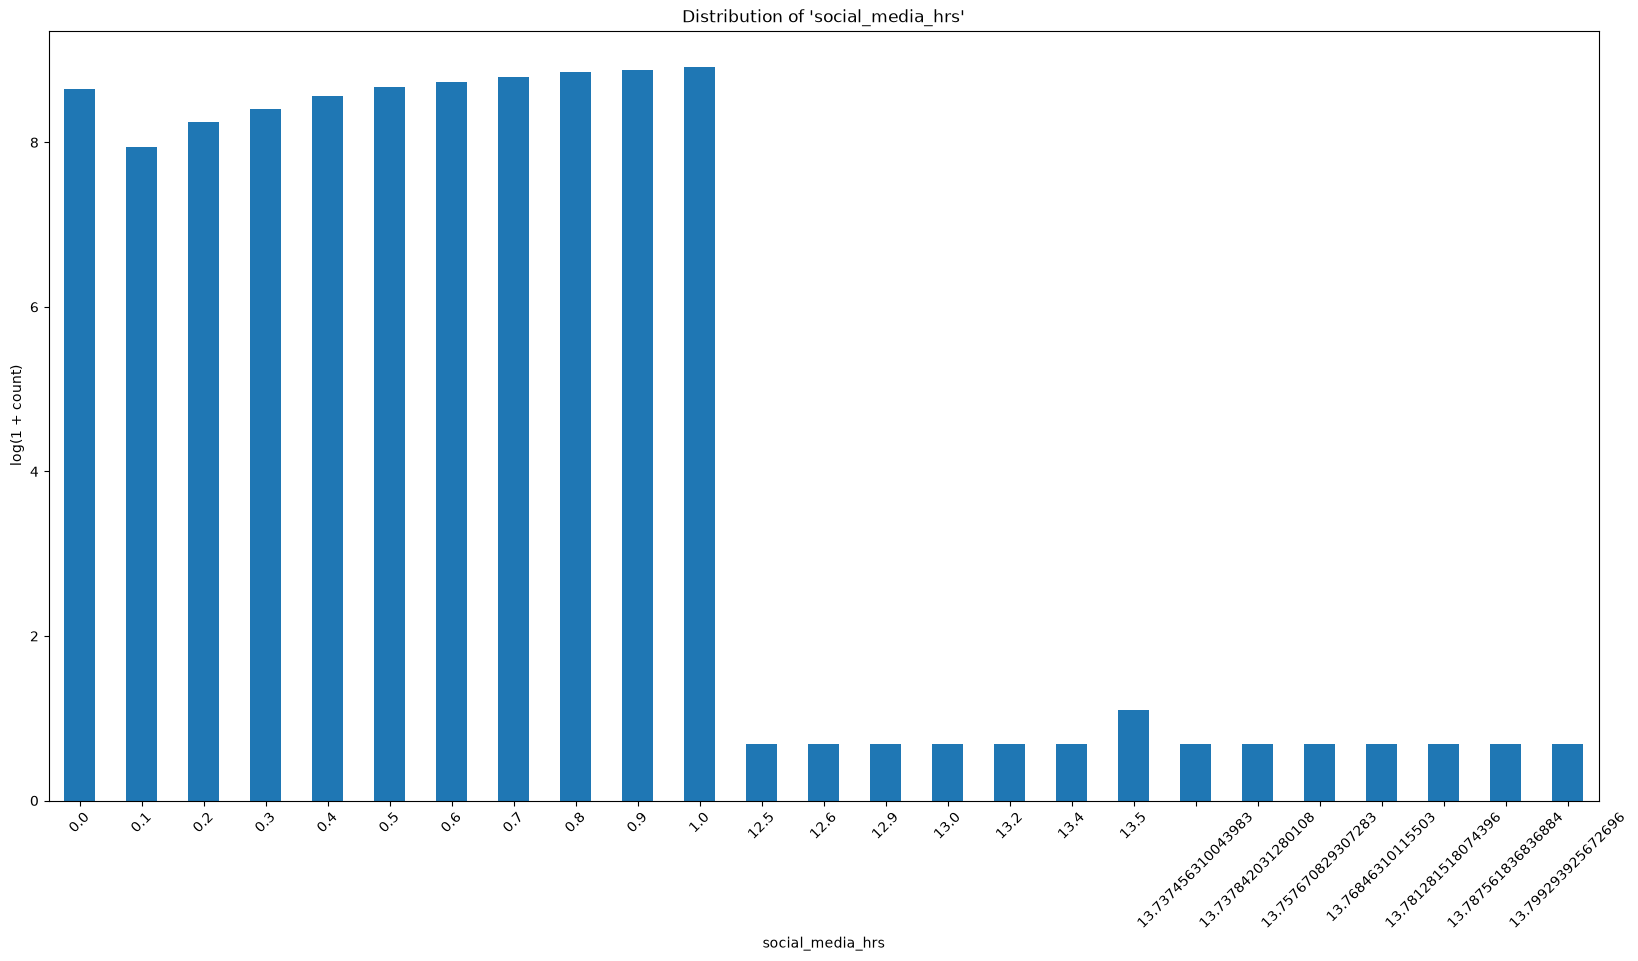

In [23]:
feature = "social_media_hrs"

# keep only values between 0–1 and 12.5–13.8
region_mask = df[feature].between(0, 1) | df[feature].between(12.5, 13.8)

plot_binned_distribution(df[region_mask], feature)

* Above 13.5 hours, the values look like noise. The valid values seem to have at most one decimal place. Let's filter the values using this criterion.

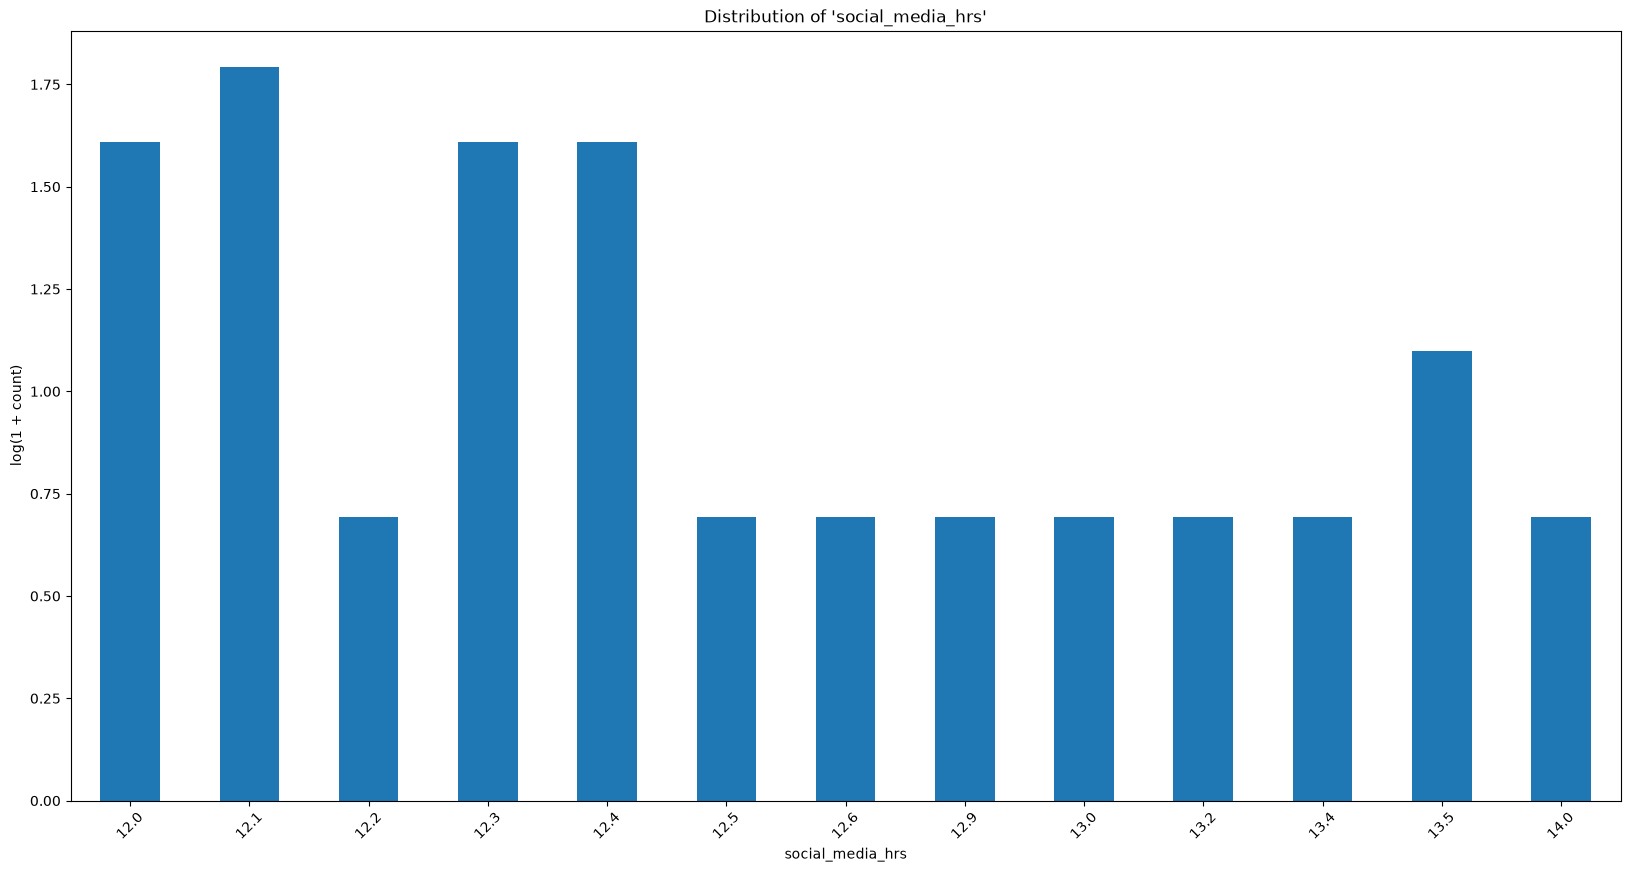

In [24]:
# keep all values between 12-18 with only one decimal place
decimal_mask = df[feature].isin(np.arange(12, 18, 0.1).round(1))

plot_binned_distribution(df[decimal_mask ], feature)

* We have only one plausible observation above 13.5 hours. However, filtering by the number of decimal places looks promising, since it separates valid and invalid values even where their ranges overlap.

#### Diet & Substance Intake

* Let's perform a similar analysis for `diet_ultra_processed_pct`.

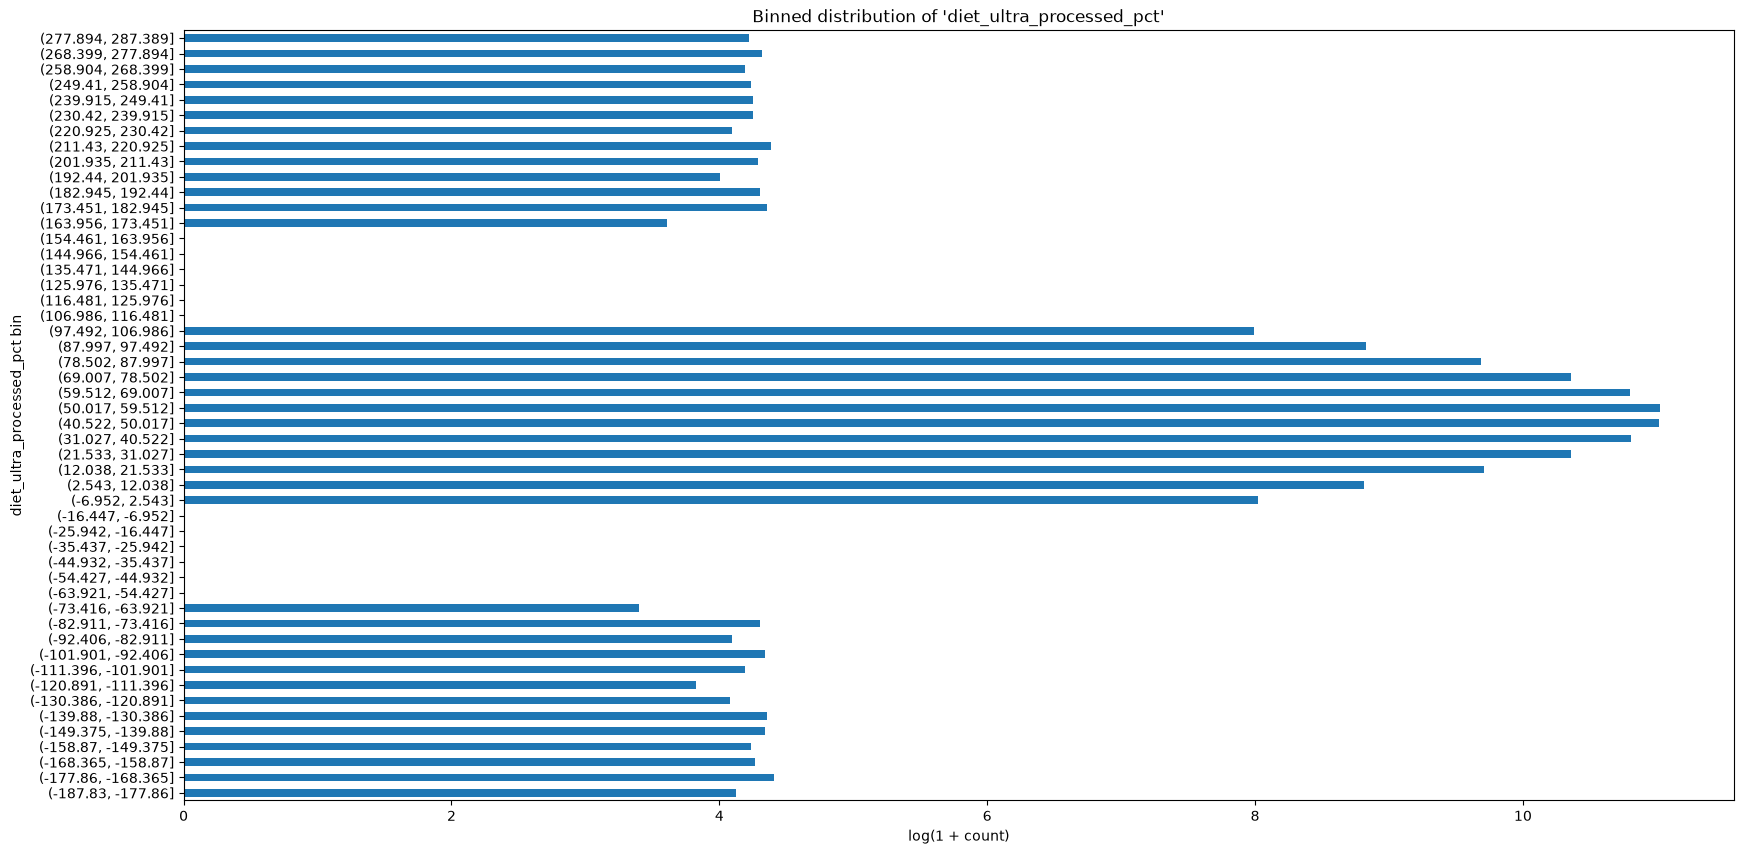

In [25]:
plot_binned_distribution(df, "diet_ultra_processed_pct")

* The valid range of `diet_ultra_processed_pct` is 0–100 percent.

* Plot the distribution of `diet_omega3_freq`.

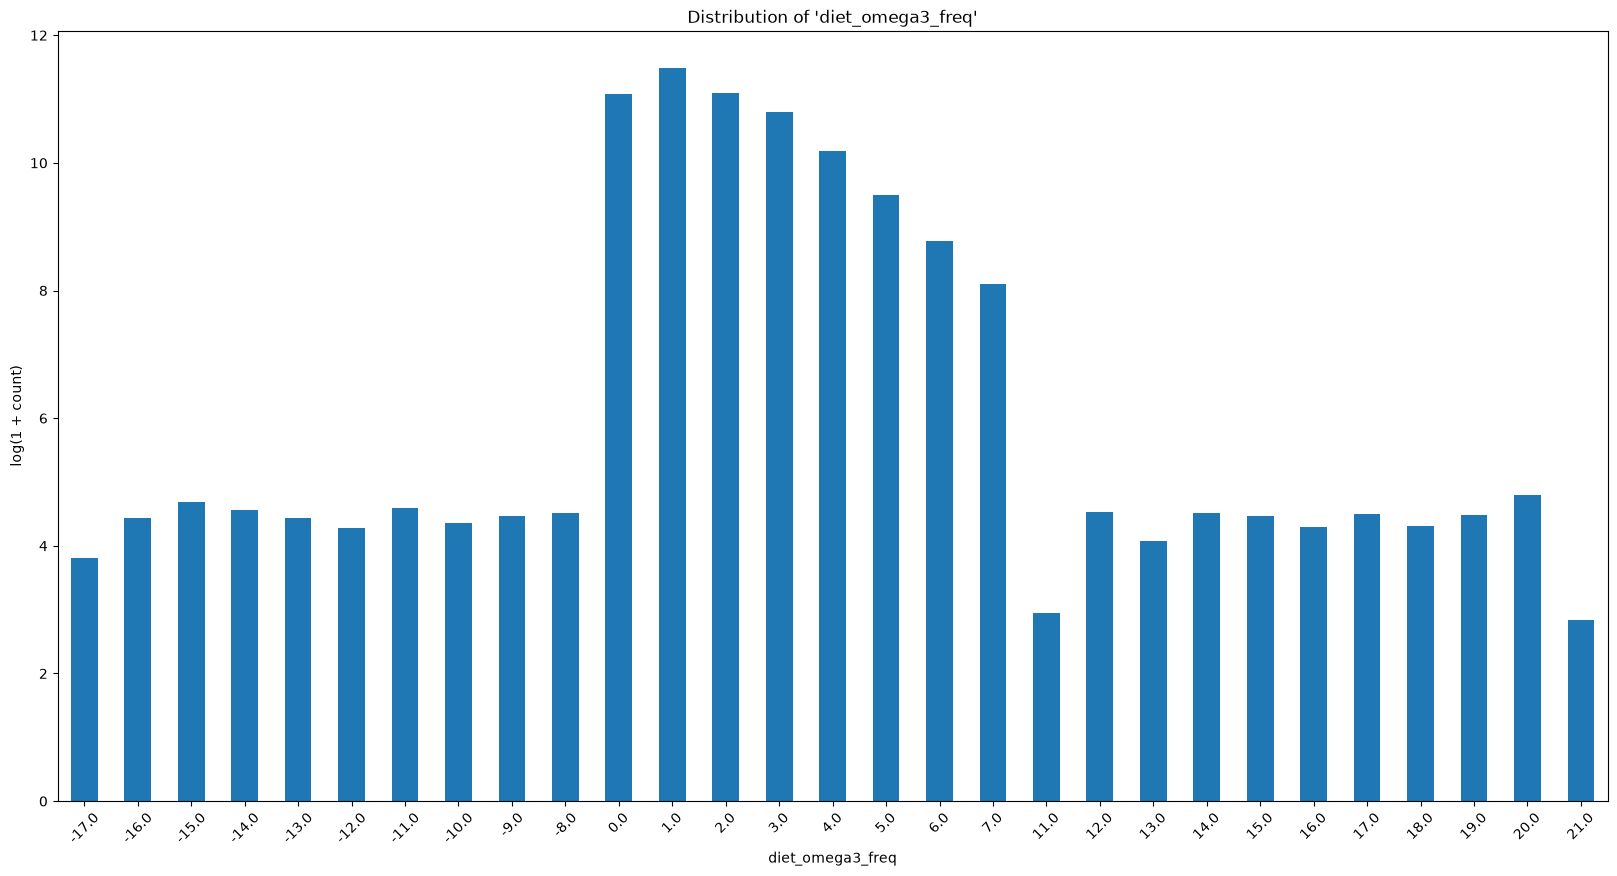

In [26]:
plot_binned_distribution(df, "diet_omega3_freq")

* The valid range of `diet_omega3_freq` is 0–7 days per week.

* Perform the same for `alcohol_drinks_wk`.

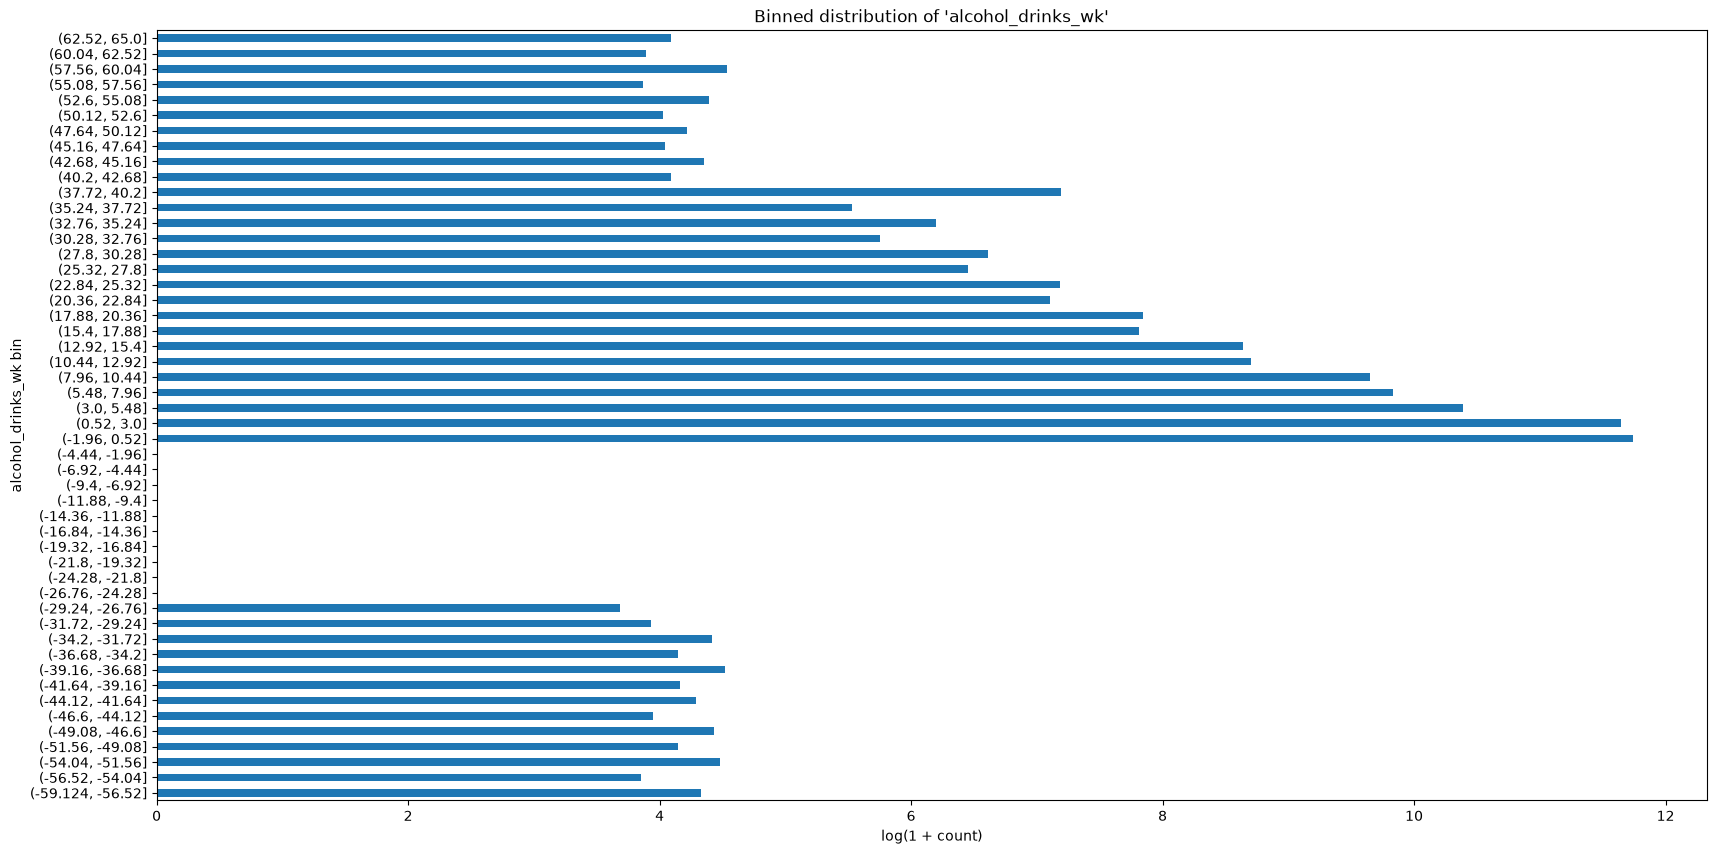

In [27]:
plot_binned_distribution(df, "alcohol_drinks_wk")

* Let's analise the cutoffs.

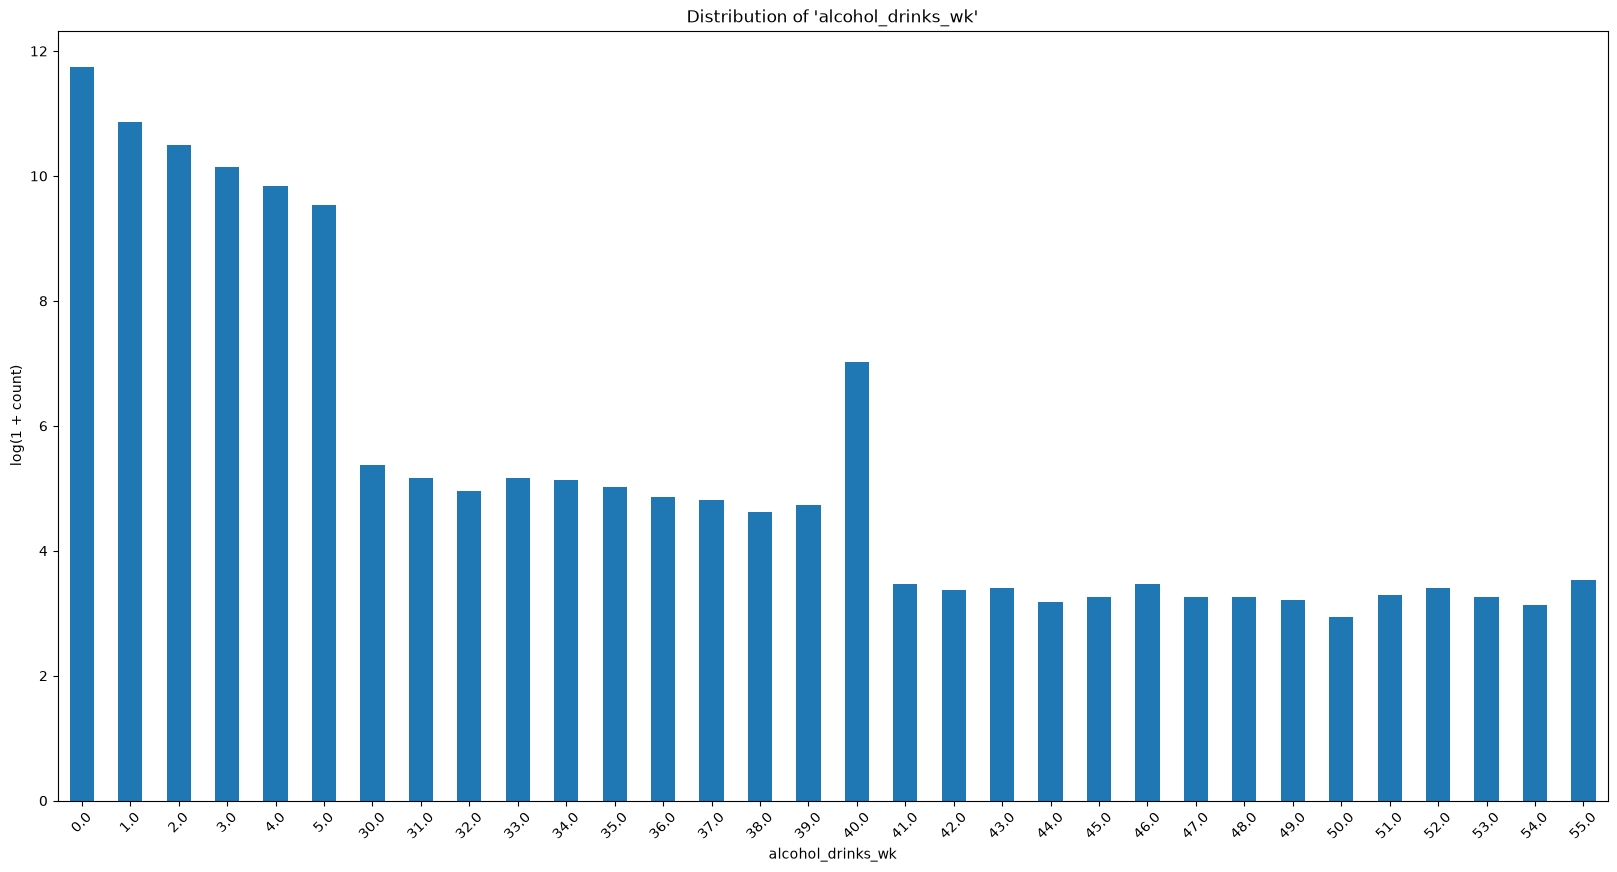

In [28]:
feature = "alcohol_drinks_wk"

# keep only values between 0–5 and 30–55
region_mask = df[feature].between(0, 5) | df[feature].between(30, 55)

plot_binned_distribution(df[region_mask ], feature)

* There is a spike at 40 drinks per week, and above that the values look like noise. A plausible upper cutoff is therefore 40.

* `smoking_status`: Let's look at the distribution of categories.

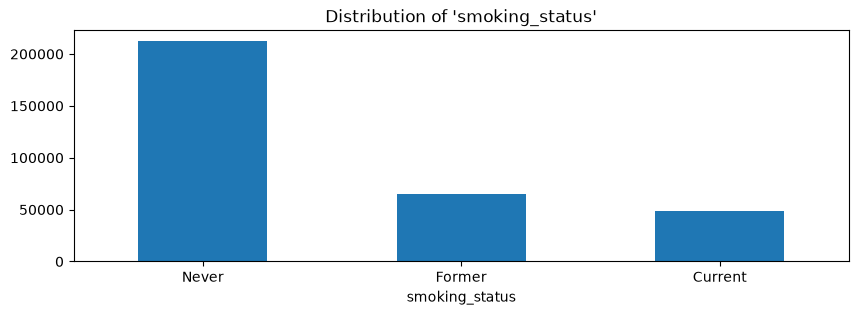

In [29]:
feature = "smoking_status"

plt.figure(figsize=(10, 3))

df[feature].value_counts().plot(
    kind="bar",
    rot=0
)

plt.title(f"Distribution of '{feature}'")
plt.show()

* Most of the participants have never smoked.

#### Neuroplasticity & Mental Health

* Let's plot the distribution of `novel_learning_hrs_wk`. 

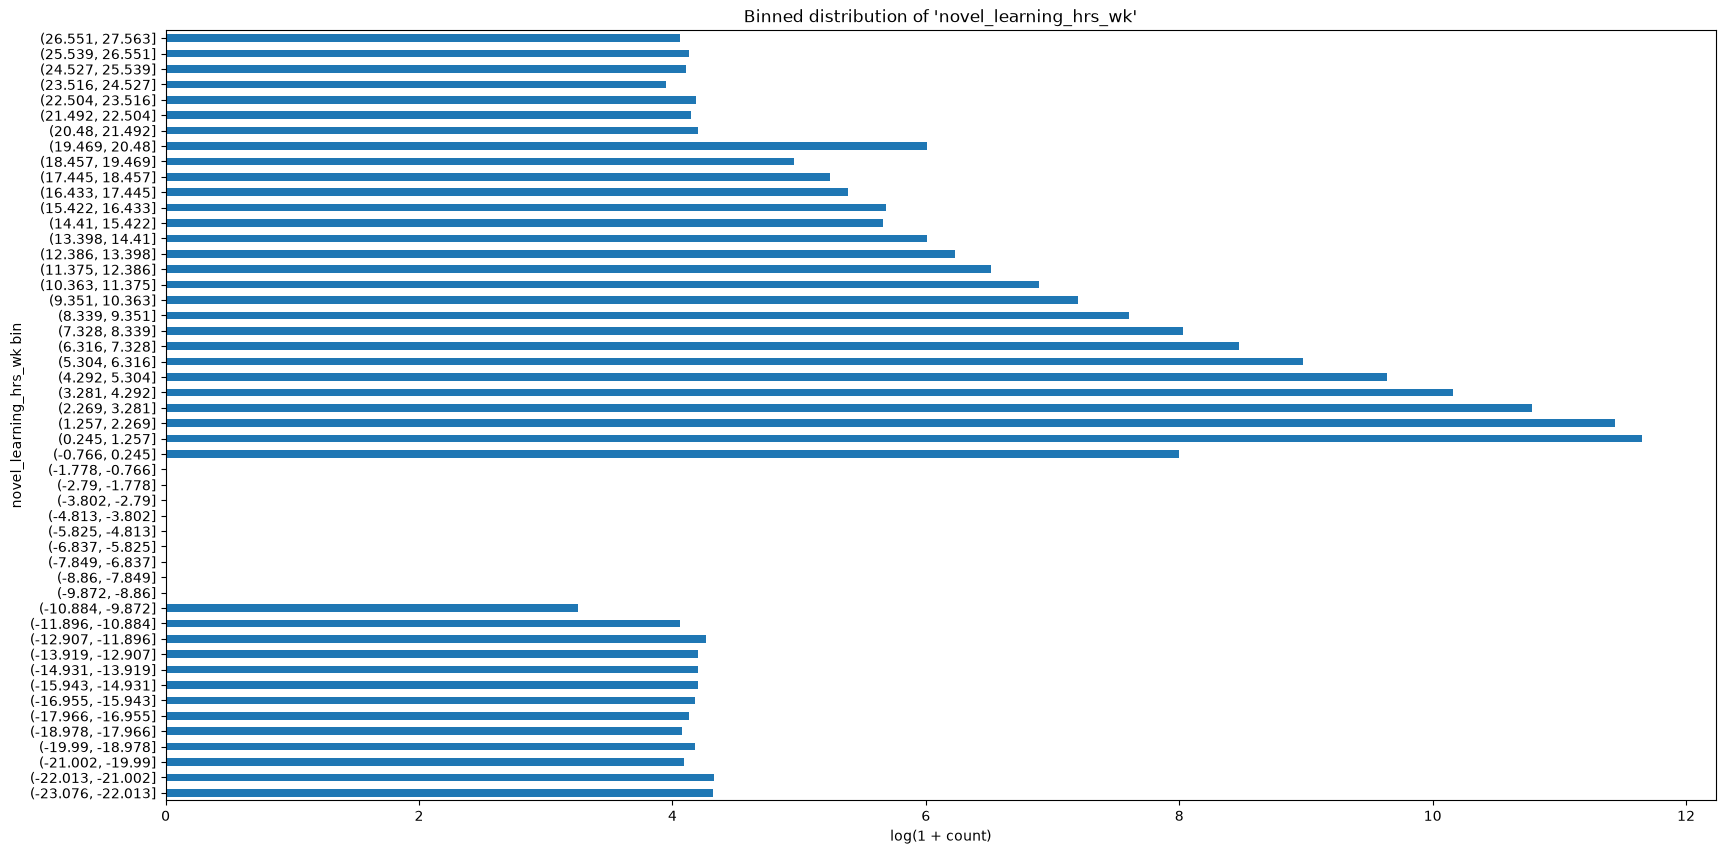

In [30]:
plot_binned_distribution(df, "novel_learning_hrs_wk")

* Here, the noise overlaps with the valid values. Let's check the most frequent values.

In [31]:
feature = "novel_learning_hrs_wk"

pd.DataFrame(df[feature].value_counts())

,count
novel_learning_hrs_wk,
0.900000,13448
0.800000,13283
1.000000,13234
0.700000,13055
1.100000,12890
...,...
-13.626666,1
25.202173,1
24.331780,1


* Again, the frequent values have at most one decimal place, while the rare ones do not. Let's examine the upper cutoff around 20 and the one-decimal-place filter.

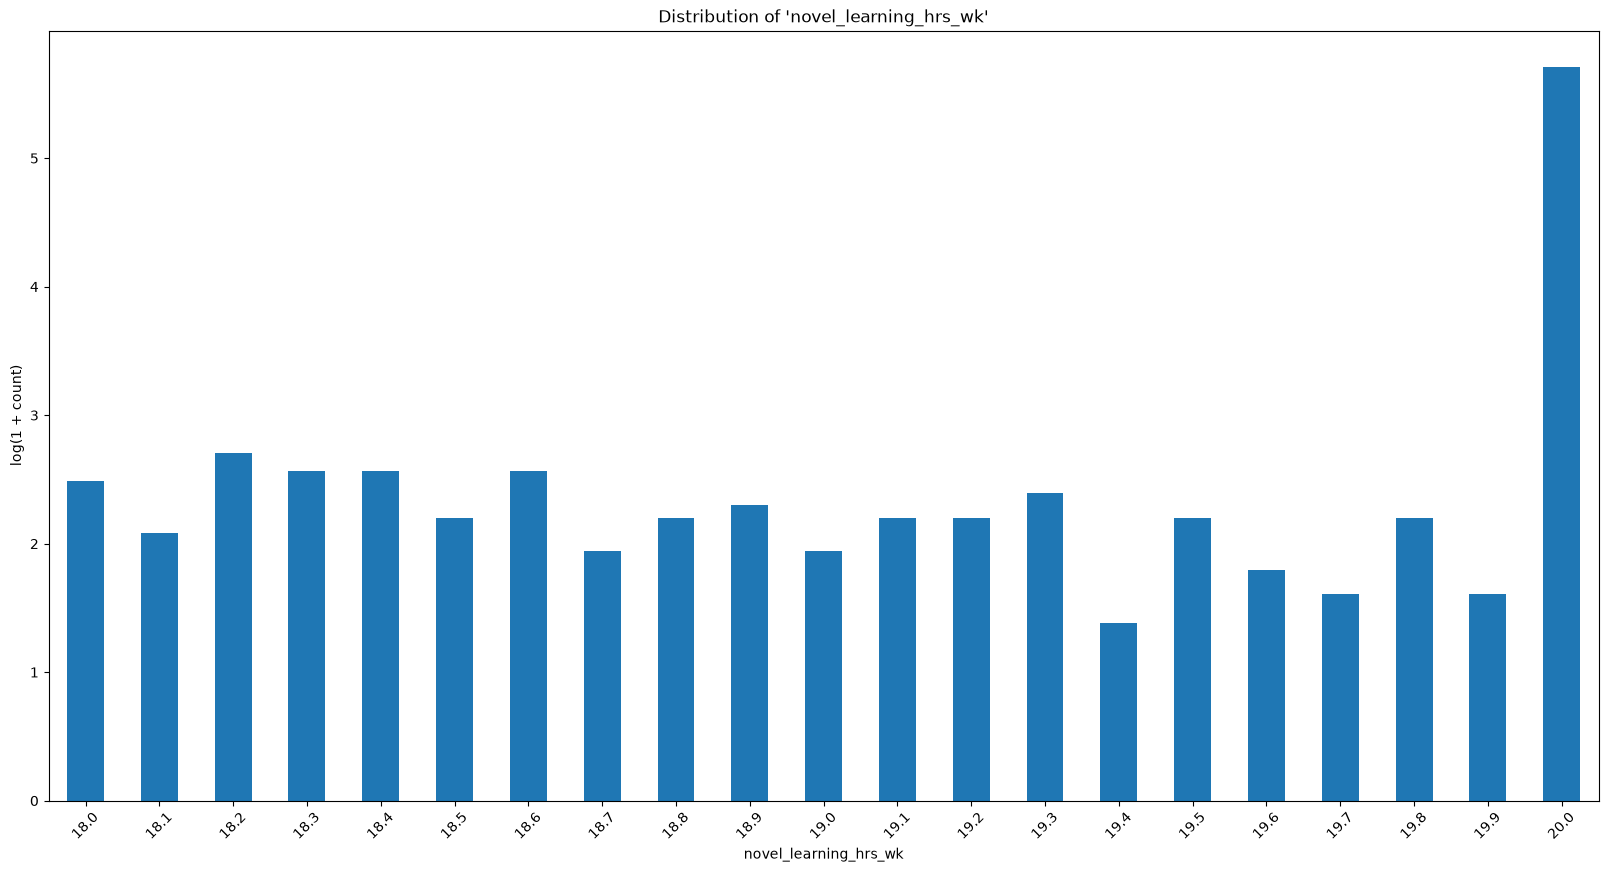

In [32]:
# keep all values between 18-22 with only one decimal place
decimal_mask = df[feature].isin(np.arange(18, 22, 0.1).round(1))

plot_binned_distribution(df[decimal_mask ], feature)

* We see a clear pattern for the real values: they go up to 20 hours, with a spike at 20.

* `social_connection_score` and `chronic_stress_score` have a valid range of 1–10. Let's plot their distributions to check this.

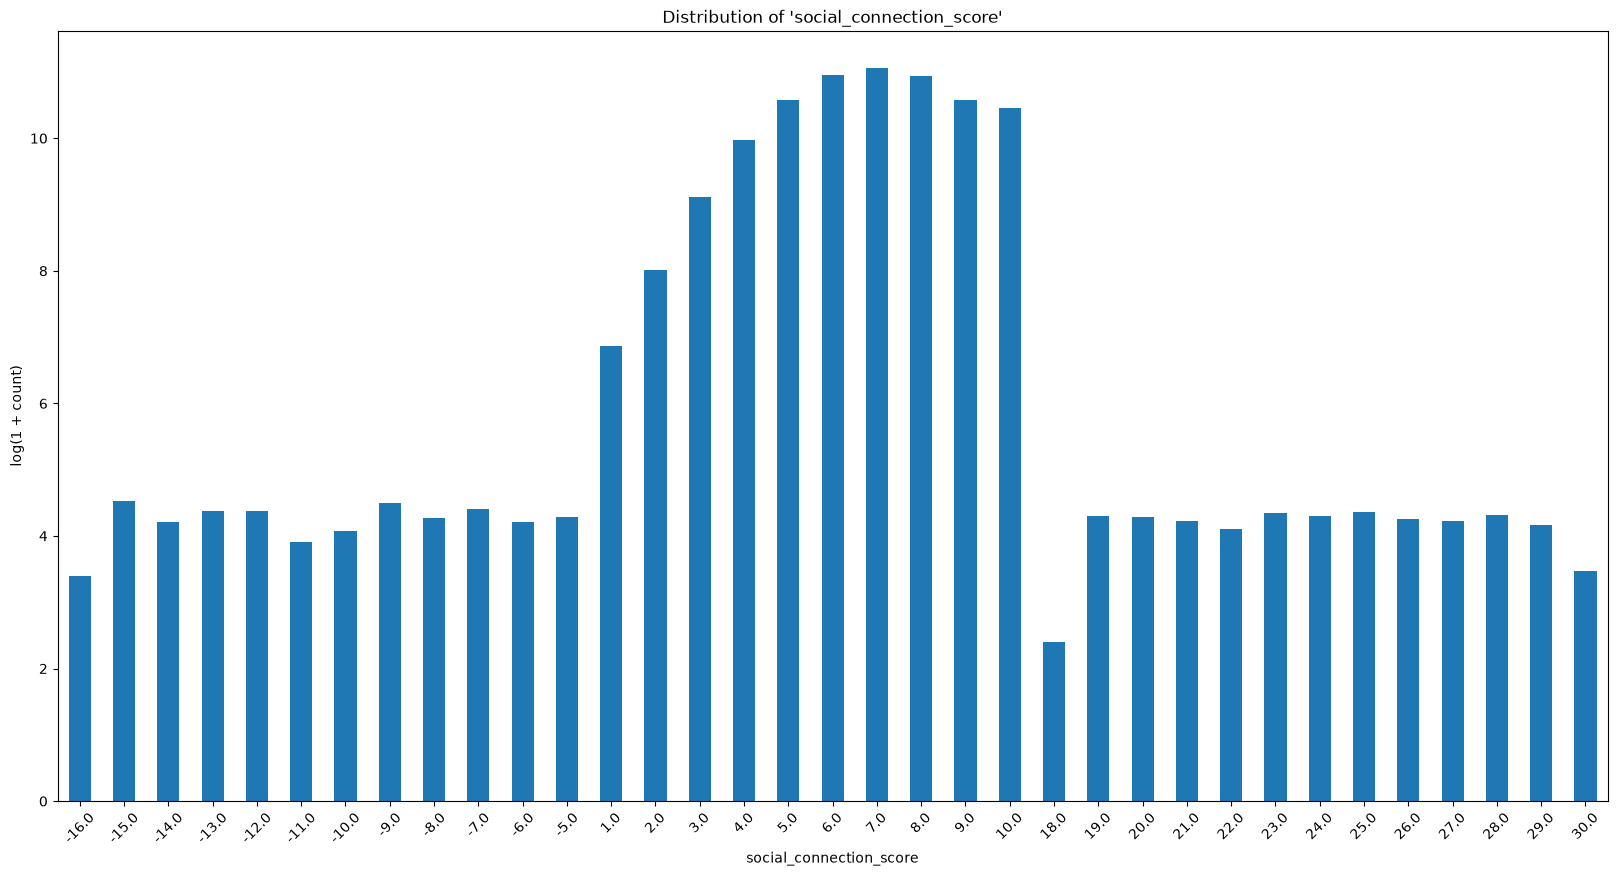

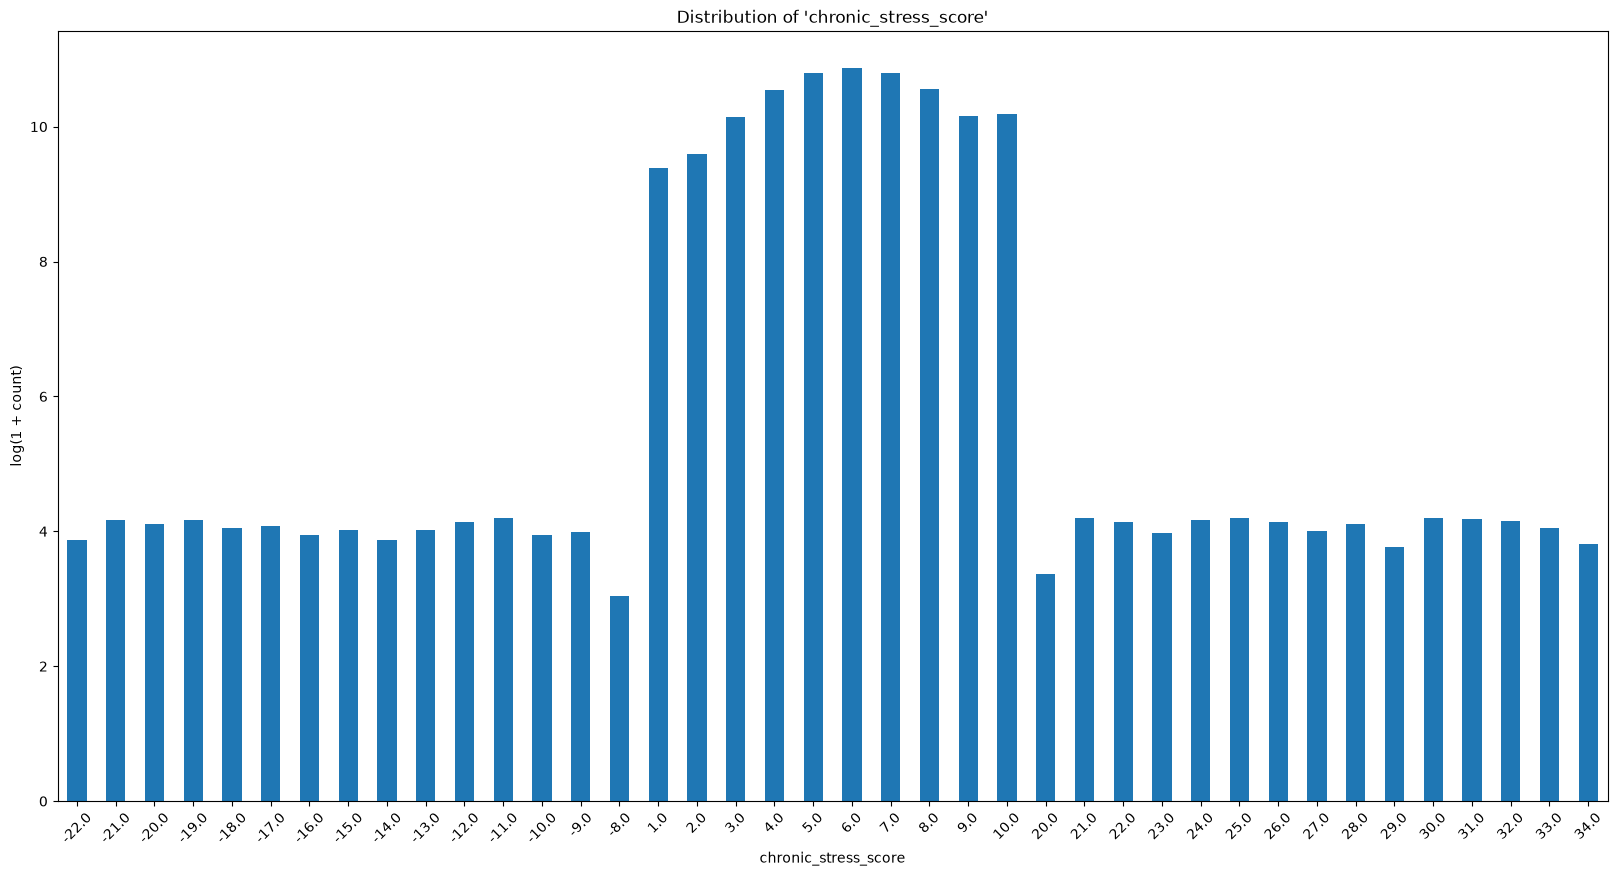

In [33]:
for feature in ["social_connection_score", "chronic_stress_score"]:
    plot_binned_distribution(df, feature)

* The distributions confirm the expected valid ranges.

#### Target

* Let's plot the distribution of the `target` feature.

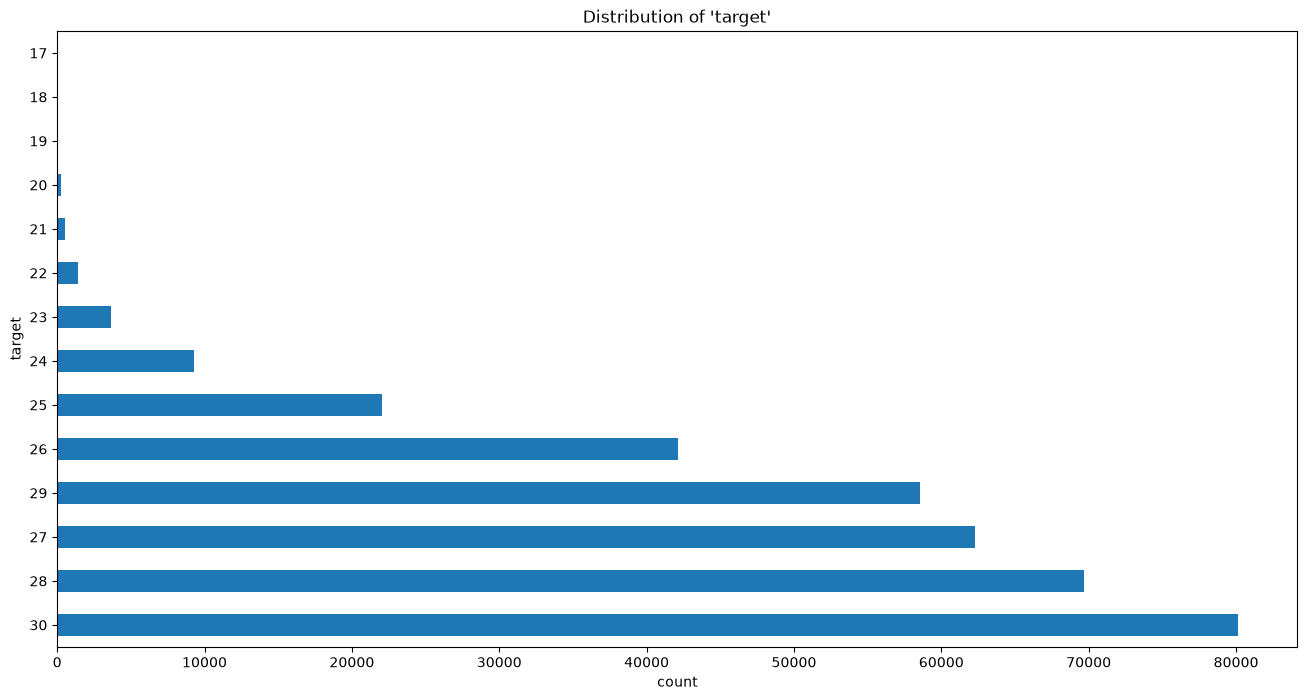

In [34]:
plt.figure(figsize=(16, 8))
df["target"].value_counts().plot.barh()
plt.title("Distribution of 'target'")
plt.xlabel("count")
plt.show()

* Nothing looks suspicious. The counts increase steadily from the minimum target value of 17 to the maximum of 30.

# Data preprocessing

### Handling invalid values

* Let's create a dictionary with all the valid ranges we have found.

In [35]:
valid_ranges = {
    "age": (18, 90),
    "blood_pressure_sys": (90, 182),
    "sleep_duration_hrs": (3, 12),
    "sleep_quality_score": (1, 10),
    "cardio_mins_wk": (0, 500),
    "water_intake_liters": (0.5, 5),
    "screen_time_recreational_hrs": (0, 16),
    "social_media_hrs": (0, 14),
    "diet_ultra_processed_pct": (0, 100),
    "diet_omega3_freq": (0, 7),
    "alcohol_drinks_wk": (0, 40),
    "novel_learning_hrs_wk": (0, 20),
    "social_connection_score": (1, 10),
    "chronic_stress_score": (1, 10)
}

* Let's also create a list of features that need the one-decimal-place filter.

In [36]:
one_decimal = ["social_media_hrs" , "novel_learning_hrs_wk"]

* Let's define a function that sets invalid values to NaN.

In [37]:
def invalid_to_nan(X, ranges, one_decimal):
    X = X.copy()

    # range check
    for col, (low, high) in ranges.items():
        X.loc[~X[col].between(low, high), col] = np.nan

    # decimal places check
    for col in one_decimal:
        s = X[col]
        X.loc[~np.isclose(s * 10, np.round(s * 10)), col] = np.nan

    return X

* Let's wrap the function in a `FunctionTransformer` to use it in our pipelines.

In [38]:
cleaner = FunctionTransformer(
    invalid_to_nan,
    kw_args={"ranges": valid_ranges, "one_decimal": one_decimal},
    feature_names_out="one-to-one", # we do not add new columns
)

* Let's compare the cleaned DataFrame with the original one.

In [39]:
missing = pd.DataFrame({
    "Original": df.isna().mean(),
    "Cleaned": cleaner.fit_transform(df).isna().mean(),
})
missing["Added"] = missing["Cleaned"] - missing["Original"]
missing

,Original,Cleaned,Added
age,0.059437,0.064077,0.004640
sleep_duration_hrs,0.073977,0.078603,0.004626
sleep_quality_score,0.026614,0.031477,0.004863
cardio_mins_wk,0.033009,0.037831,0.004823
water_intake_liters,0.023143,0.027994,0.004851
screen_time_recreational_hrs,0.078017,0.082623,0.004606
social_media_hrs,0.014420,0.019340,0.004920
blood_pressure_sys,0.026314,0.031146,0.004831
diet_ultra_processed_pct,0.036191,0.041049,0.004857
diet_omega3_freq,0.061306,0.065991,0.004686


* All numerical features have a similar share of outliers.

### Handling missing values and feature preprocessing

* For numerical features, we will use a median imputer.

In [117]:
num_features = list(df.columns.drop(["smoking_status", "target"]))

* For the categorical feature `smoking_status`, we will use a most-frequent imputer and an ordinal encoder.

In [118]:
cat_features = ["smoking_status"]

### Additional feature preprocessing

* `smoking_status` will be ordinal encoded.

* For linear models, we will standardize the numerical features.

# Pipeline A

* After cleaning and preprocessing, we apply `PolynomialFeatures`, `StandardScaler` and a `Ridge` regressor.

* The hyperparameters include the degree of the polynomial features and the strength of the Ridge regularization.

In [189]:
# Define features and target
X = df.drop(columns=["target"])
y = df["target"]

# Preprocessing of numerical features
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

# Preprocessing of categorical features
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=[["Never", "Former", "Current"]])),
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline, cat_features)
])

# Pipeline for cross-validation
model = Pipeline([
    ("cleaner", cleaner),
    ("preprocessor", preprocessor),
    ("polynomial", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Hyperparameter ranges
param_grid = {
    "polynomial__degree": [1, 2, 3],
    "ridge__alpha": [1, 3, 10, 30, 100],
}

# Cross-validation with 3 folds
cv = KFold(n_splits=3, shuffle=True, random_state=42)

# Search for optimal hyperparameters
search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
)

search.fit(X, y)

# Best model
final_lin_model = search.best_estimator_

print(f"Best MAE score: {-search.best_score_:.5f}")
print(f"Best hyperparameters: {search.best_params_}")

python(61725) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61726) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61727) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61728) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61729) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61730) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61731) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61732) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
/Users/aygulminnegalieva/zaur_ws/NMBU/DAT200/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be cau

Best MAE score: 0.90470
Best hyperparameters: {'polynomial__degree': 3, 'ridge__alpha': 10}


# Pipeline B

### Target binning

* Let's define a function to bin the numeric target variable.

In [ ]:
def bin_target(target, num_bins):

    binned_target = pd.qcut(
        target,
        num_bins,
        labels=False,
        duplicates="drop" # drop identical delimeters (decreases the real number classes)
    )

    medians = target.groupby(binned_target).median()  # medians of bins to calculate MAE

    return binned_target, medians

* Let's build a pipeline for `RandomForestClassifier`.

In [169]:
# Features and target
X = df.drop(columns=["target"])
y = df["target"]

# Split data for the final MAE evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

# Numerical preprocessing
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=[["Never", "Former", "Current"]])),
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline, cat_features)
])

# Complete pipeline
model = Pipeline([
    ("cleaner", cleaner),
    ("preprocessor", preprocessor),
    ("rf", RandomForestClassifier(n_estimators=150, random_state=42))
])

# Hyperparameters
param_grid = {
    "rf__max_features": ["sqrt", 0.3, 0.5, 0.7],
    "rf__min_samples_leaf": [1, 2, 5, 10, 20, 50, 100],
    "rf__max_samples": np.linspace(0.3, 0.9, 7).round(2).tolist(),
    "rf__class_weight": [None, "balanced"],
}

# Cross-validation parameters
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

* Let's compare different binning strategies.

In [170]:
strategies = [(f"{n} bins", n) for n in [2, 3, 4, 6, 10]] + [("no binning", None)]

rows = []
for name, n_bins in strategies:

    # Bin the training target
    if n_bins is None:
        binned_target = y_train
    else:
        binned_target, medians = bin_target(y_train, n_bins)

    # Tune the hyperparameters (20 trials)
    search = RandomizedSearchCV(
        model,
        param_grid,
        n_iter=20,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
        random_state=42,
    )
    search.fit(X_train, binned_target)

    # Test MAE
    predicted_bins = search.predict(X_test)
    if n_bins is None:
        y_predict = predicted_bins
    else:
        y_predict = medians.loc[predicted_bins].to_numpy()
    test_mae = mean_absolute_error(y_test, y_predict)

    # Save the best model for the strategy
    rows.append({
        "strategy": name,
        "n_classes": binned_target.nunique(),
        "cv_mae": -search.best_score_,
        "test_mae": test_mae,
        "best_params": search.best_params_,
    })

results = pd.DataFrame(rows).sort_values("test_mae").set_index("strategy")
results

python(61323) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61324) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61325) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61326) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61327) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61328) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61329) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61330) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(61371) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
/Users/aygulminnegalieva/zaur_ws/NMBU/DAT200/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor

,n_classes,cv_mae,test_mae,best_params
strategy,,,,
no binning,14,0.918436,0.910457,"{'rf__min_samples_leaf': 20, 'rf__max_samples'..."
10 bins,6,0.869125,0.930143,"{'rf__min_samples_leaf': 20, 'rf__max_samples'..."
6 bins,5,0.772936,0.945143,"{'rf__min_samples_leaf': 10, 'rf__max_samples'..."
4 bins,4,0.597618,0.988329,"{'rf__min_samples_leaf': 10, 'rf__max_samples'..."
3 bins,3,0.363186,1.040443,"{'rf__min_samples_leaf': 10, 'rf__max_samples'..."
2 bins,2,0.209389,1.108171,"{'rf__min_samples_leaf': 20, 'rf__max_samples'..."


* The test MAE decreases as the number of bins increases, and the model without binning performs best.

In [185]:
best = results.loc["no binning"]
best_params = best["best_params"]
pd.DataFrame(best_params, index=["Optimal value"]).T

,Optimal value
rf__min_samples_leaf,20
rf__max_samples,0.5
rf__max_features,0.7
rf__class_weight,None


* Let's retrain the best model on the whole training set.

In [173]:
final_cls_model = clone(model).set_params(**best_params)
final_cls_model.set_params(rf__n_estimators=300)  # increase stability
final_cls_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](14,)","[17,18,19,...,28,29,30]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','sleep_duration_hrs','sleep_quality_score',..., 'novel_learning_hrs_wk','social_connection_score','chronic_stress_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function inv...t 0x13a119c60>
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18","{'one_decimal': ['social_media_hrs', 'novel_learning_hrs_wk'], 'ranges': {'age': (18, ...), 'alcohol_drinks_wk': (0, ...), 'blood_pressure_sys': (90, ...), 'cardio_mins_wk': (0, ...), ...}}"


# Pipeline C

# Model comparison and evaluation

# Kaggle submission

In [187]:
final_X_test = pd.read_csv("data/test.csv", index_col=0)

### Pipeline A

In [188]:
y_pred = final_lin_model.predict(final_X_test)

df_sub = pd.DataFrame({"target": y_pred}, index=final_X_test.index)
df_sub.to_csv("data/lin_sub.csv", index=True)

### Pipeline B

In [176]:
y_pred = final_cls_model.predict(final_X_test)

df_sub = pd.DataFrame({"target": y_pred}, index=final_X_test.index)
df_sub.to_csv("data/cls_sub.csv", index=True)